# Trabajo final de Big Data

Dan Carrión · Matrícula 1131022 · INTEC

30 visualizaciones con Northwind, HR y sensores. **Origen:** scripts oficiales extraídos sin conexión a motores; sensores sintéticos, semilla 5122026. Las evidencias de conexión deben completarse con `src/conexiones.py`. La ejecución siguiente reconstruye datos y gráficos locales; no escribe en bases de datos.

In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
root = Path.cwd()
if (root / 'proyecto_final').is_dir():
    root = root / 'proyecto_final'
assert (root / 'src/analisis.py').exists(), 'Abre Jupyter desde la carpeta del proyecto'
print('Proyecto:', root)

Proyecto: /Users/dancarrion/Documents/ChatGPT/Big Data/proyecto_final


## Preparación y análisis

Los scripts leen los originales, generan la simulación, calculan las tablas analíticas y crean figuras sobre esos mismos cálculos.

In [2]:
# Si los CSV vienen de los gestores (run.py --desde-bd), no se reconstruyen las muestras.
fuentes = root / 'data/procesados/proveniencia_fuentes.json'
extraido = fuentes.exists() and any(r.get('mode') == 'base_de_datos' for r in json.loads(fuentes.read_text()).values())
scripts = ['analisis.py', 'dashboard.py', 'validar.py'] if extraido else ['preparar_datos.py', 'analisis.py', 'dashboard.py', 'validar.py']
for script in scripts:
    result = subprocess.run([sys.executable, str(root / 'src' / script)], cwd=root, capture_output=True, text=True, check=True)
    print(script)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)

preparar_datos.py
{"nw_Categories": 8, "nw_Customers": 91, "nw_Employees": 9, "nw_Order Details": 2155, "nw_Orders": 830, "nw_Products": 77, "nw_Shippers": 3, "nw_Suppliers": 29, "hr_regions": 5, "hr_countries": 25, "hr_locations": 23, "hr_departments": 27, "hr_jobs": 19, "hr_employees": 107, "hr_job_history": 10, "sensores": 12960}



analisis.py
{
  "nw": {
    "orders": 830,
    "lines": 2155,
    "customers": 91,
    "active_customers": 89,
    "net": 1265793.0395,
    "gross": 1354458.59,
    "discount_amount": 88665.55050000001,
    "period": [
      "1996-07-04",
      "1998-05-06"
    ]
  },
  "hr": {
    "employees": 107,
    "salary_mean": 6461.8317757009345,
    "salary_median": 6200.0,
    "unassigned": 1,
    "sum_salary": 691416.0
  },
  "sensors": {
    "rows": 12960,
    "stations": 6,
    "sensors": 18,
    "tp": 103,
    "fp": 34,
    "fn": 0,
    "precision": 0.7518248175182481,
    "recall": 1.0,
    "alerts": 137,
    "injected": 103
  }
}

/Users/dancarrion/Documents/ChatGPT/Big Data/proyecto_final/src/analisis.py:27: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(ROOT/'figuras'/f'{id}.png',dpi=165,bbox_inches='tight'); plt.close(fig)



dashboard.py
Dashboard listo: /Users/dancarrion/Documents/ChatGPT/Big Data/proyecto_final/dashboard/index.html



validar.py
17/17 comprobaciones correctas



## Resultados comprobables

Los indicadores provienen de cálculos sobre las muestras. La evaluación de anomalías usa el mismo mes para referencia y revisión: es retrospectiva.

In [3]:
results = json.loads((root / 'docs/resultados.json').read_text())
print(json.dumps(results, indent=2, ensure_ascii=False))
checks = json.loads((root / 'evidencias/validacion.json').read_text())
assert checks['passed']
print('Comprobaciones correctas:', len(checks['checks']))

{
  "nw": {
    "orders": 830,
    "lines": 2155,
    "customers": 91,
    "active_customers": 89,
    "net": 1265793.0395,
    "gross": 1354458.59,
    "discount_amount": 88665.55050000001,
    "period": [
      "1996-07-04",
      "1998-05-06"
    ]
  },
  "hr": {
    "employees": 107,
    "salary_mean": 6461.8317757009345,
    "salary_median": 6200.0,
    "unassigned": 1,
    "sum_salary": 691416.0
  },
  "sensors": {
    "rows": 12960,
    "stations": 6,
    "sensors": 18,
    "tp": 103,
    "fp": 34,
    "fn": 0,
    "precision": 0.7518248175182481,
    "recall": 1.0,
    "alerts": 137,
    "injected": 103
  }
}
Comprobaciones correctas: 17


## SQL Server / Northwind

Cada figura se acompaña de método, resultado y límite. Los scripts de consulta están en `sql/` y `mongo/`.

N01 · Ventas mensuales y tendencia
Método: Se suma precio de línea × cantidad × (1 - descuento) por mes. La tendencia promedia tres observaciones mensuales consecutivas; conserva los períodos parciales y requiere tres observaciones.


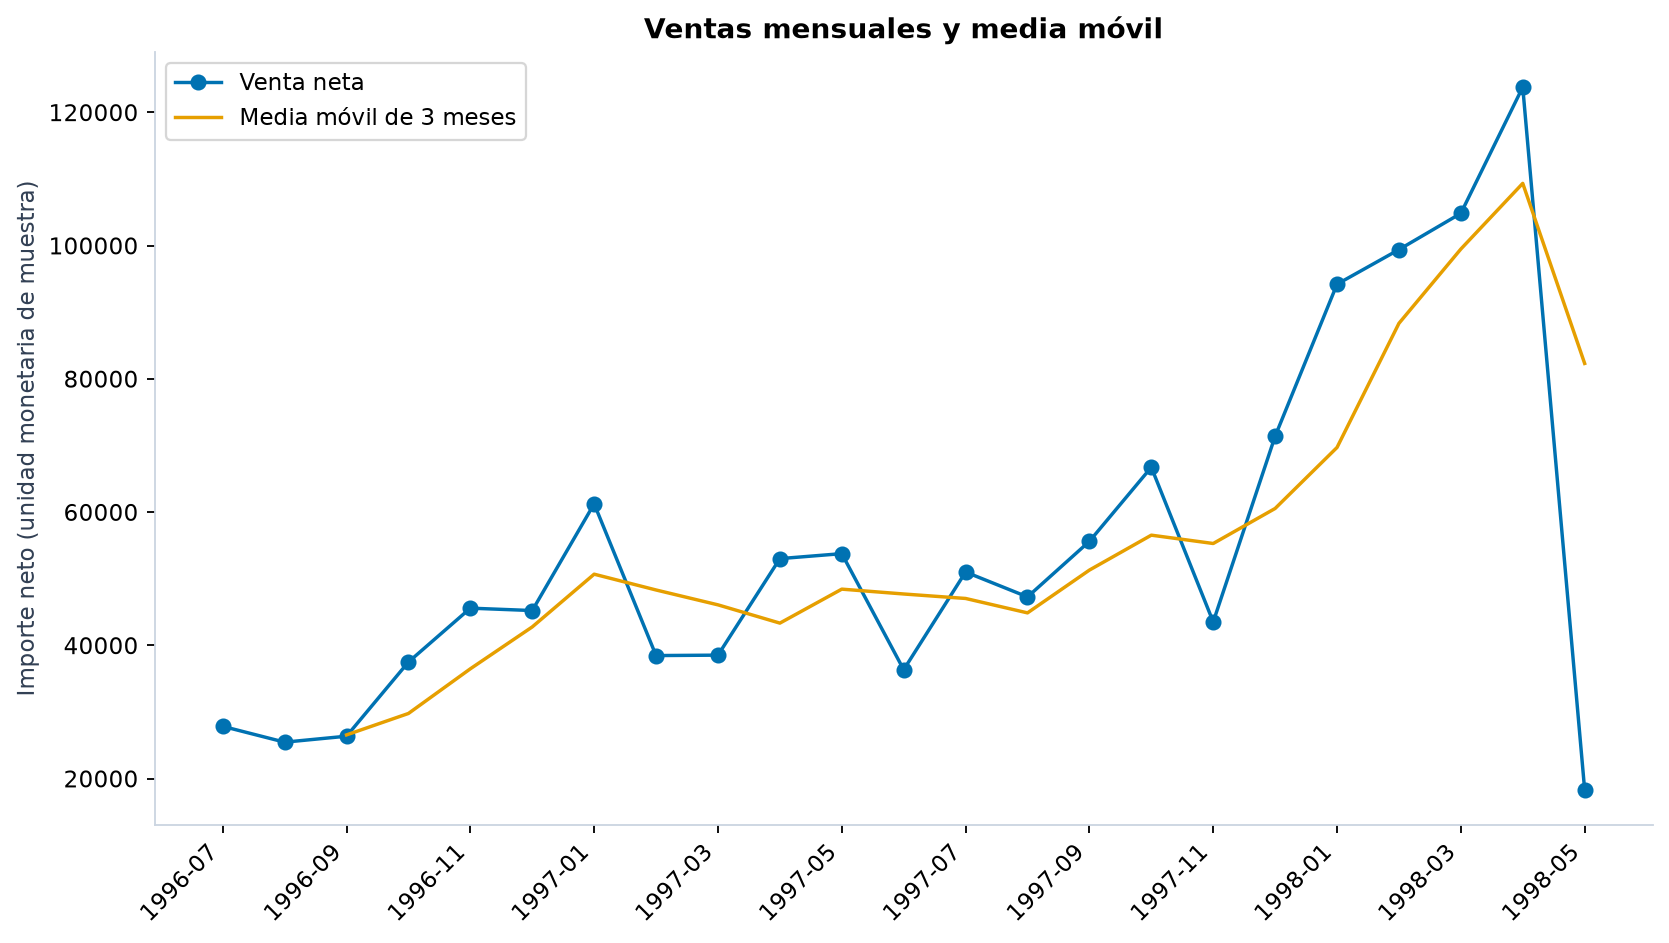

Resultado: El total neto es 1,265,793.04; el máximo mensual corresponde a 1998-04, con 123,798.68.
Decisión: Ajustar inventario y capacidad para meses de mayor demanda, confirmando el patrón con un período más amplio.
Límite: Julio de 1996 y mayo de 1998 son períodos parciales. Las ventas no incluyen flete, impuestos ni costos. No se interpreta el último mes como caída económica.

N02 · Mapa de calor: categoría y país
Método: Se cruzan categorías con los ocho países con mayor venta neta. El color representa importe en miles; país es el domicilio del cliente.


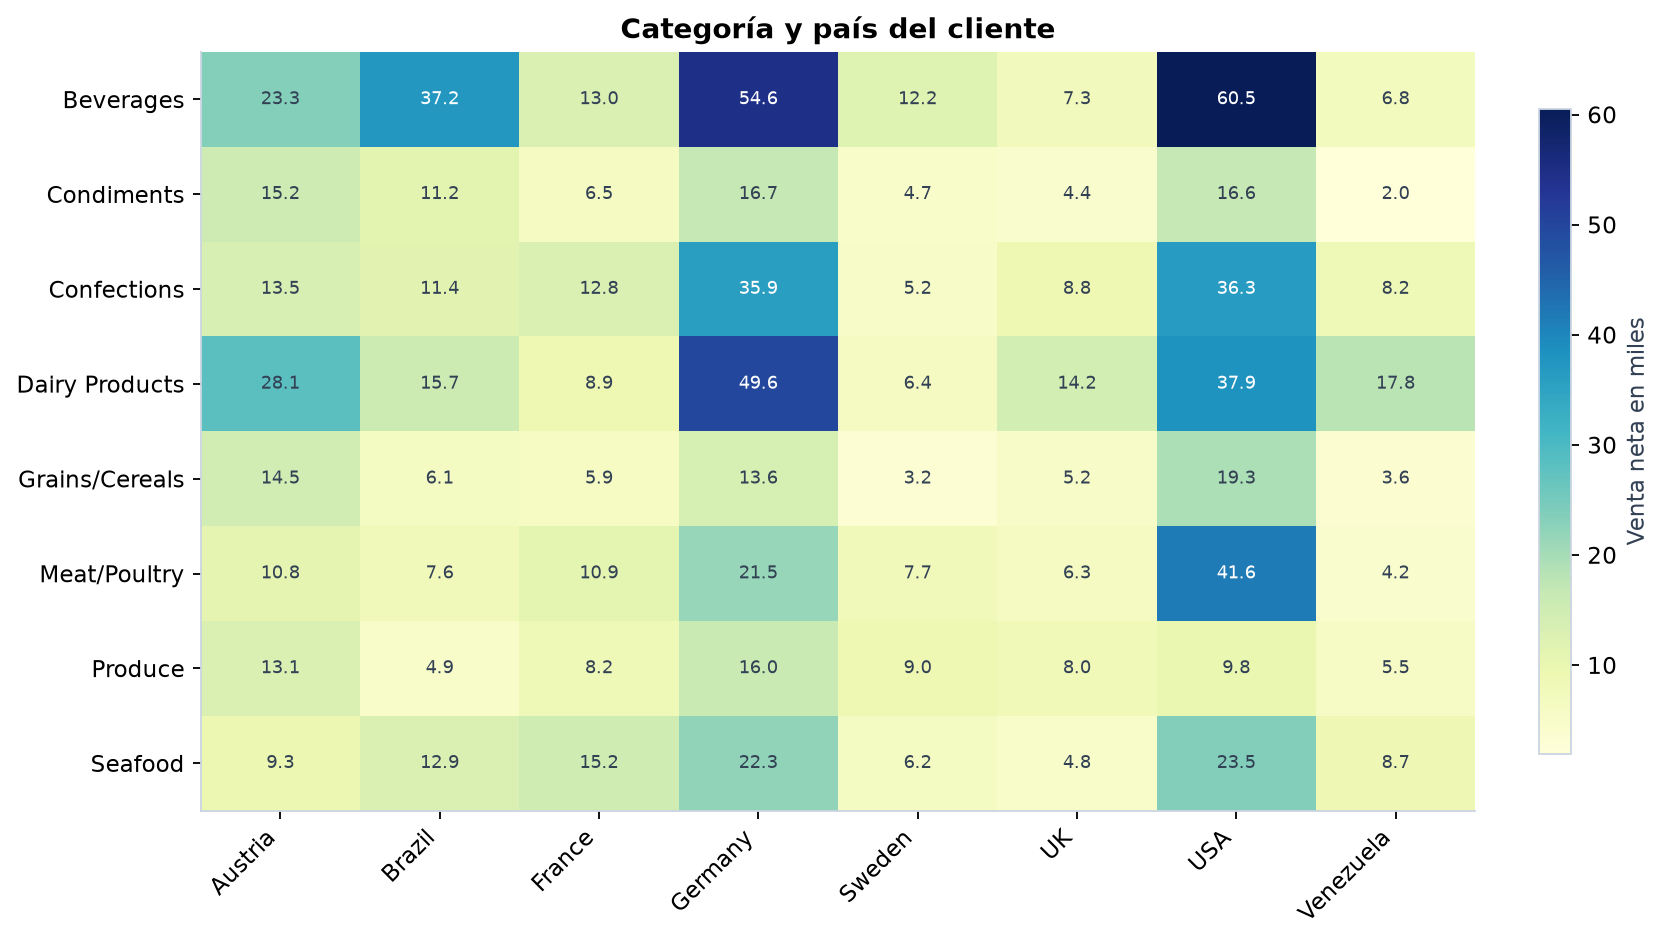

Resultado: Beverages lidera por categoría con 267,868.18, equivalente al 21.2% del total.
Decisión: Adaptar el portafolio a las combinaciones de mercado y categoría con mayor facturación.
Límite: No se incluye el resto de países en la matriz. Una celda elevada puede resultar de pocos pedidos grandes; no equivale a mayor penetración de mercado.

N03 · Top 10 clientes por volumen monetario
Método: Se agrupan las líneas por cliente y se ordena la suma de venta neta. Volumen se define aquí como importe, no unidades.


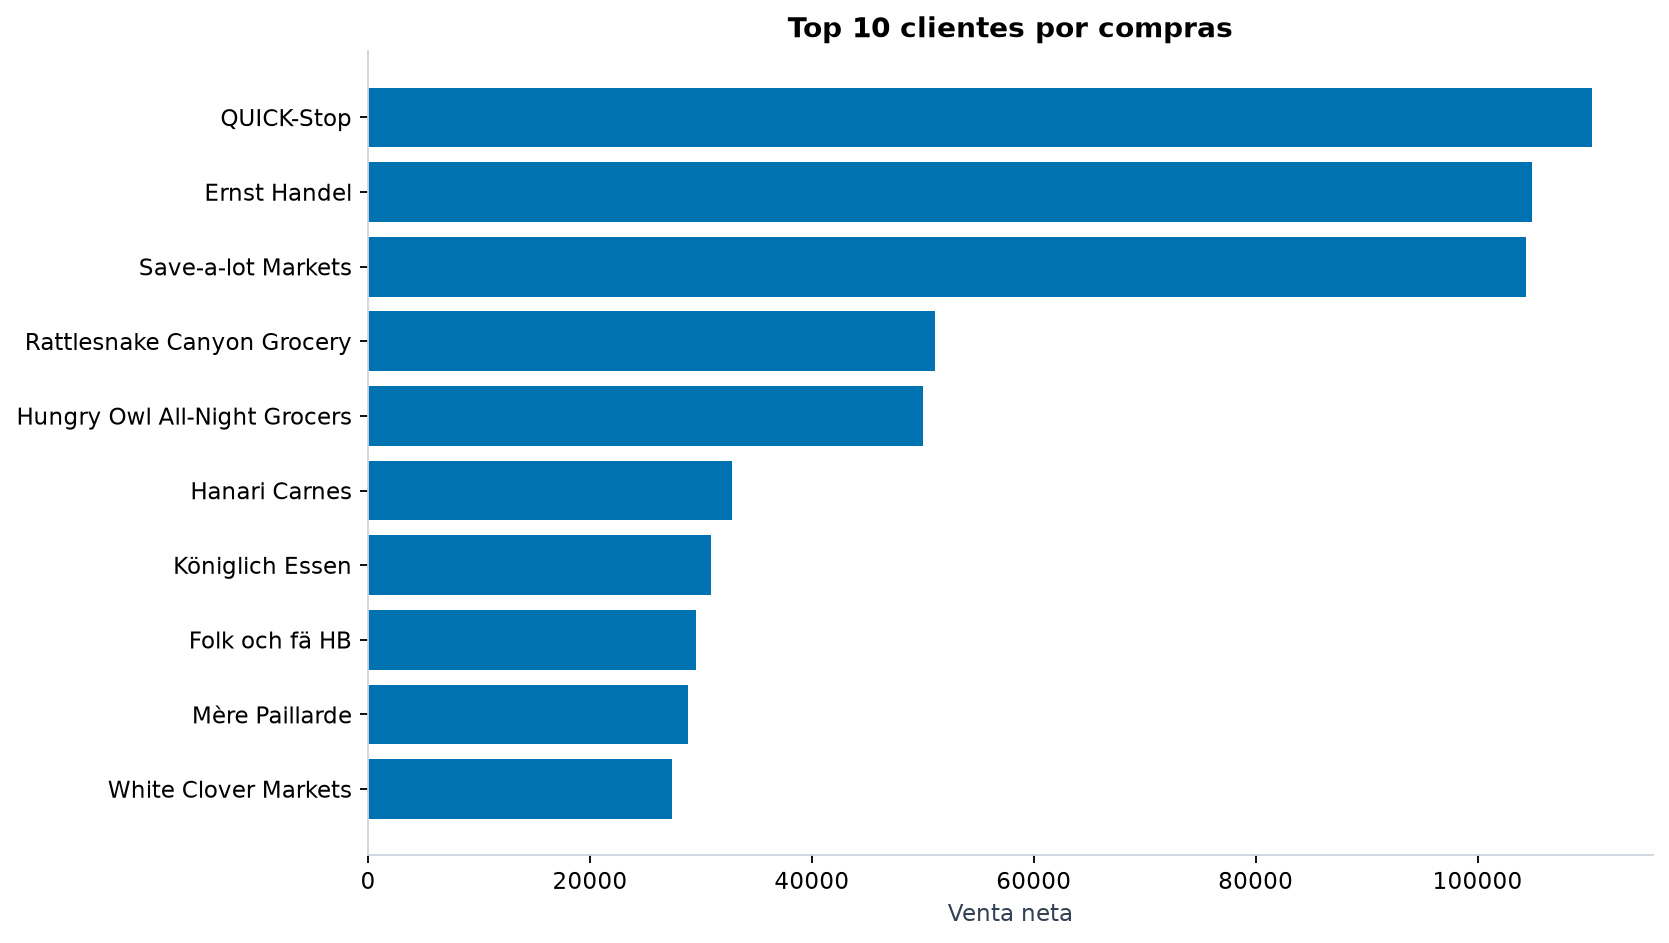

Resultado: QUICK-Stop encabeza las compras con 110,277.31. Los diez primeros concentran 45.0% de las ventas.
Decisión: Diseñar seguimiento de cuentas clave y evaluar riesgo de concentración.
Límite: El ranking histórico no mide fidelidad ni valor futuro. Dos clientes del catálogo no tienen pedidos y aportan cero al análisis comercial.

N04 · Evolución de ventas trimestrales
Método: Cada pedido se asigna al trimestre de OrderDate; la suma se calcula a partir de líneas, sin multiplicar pedidos por uniones adicionales.


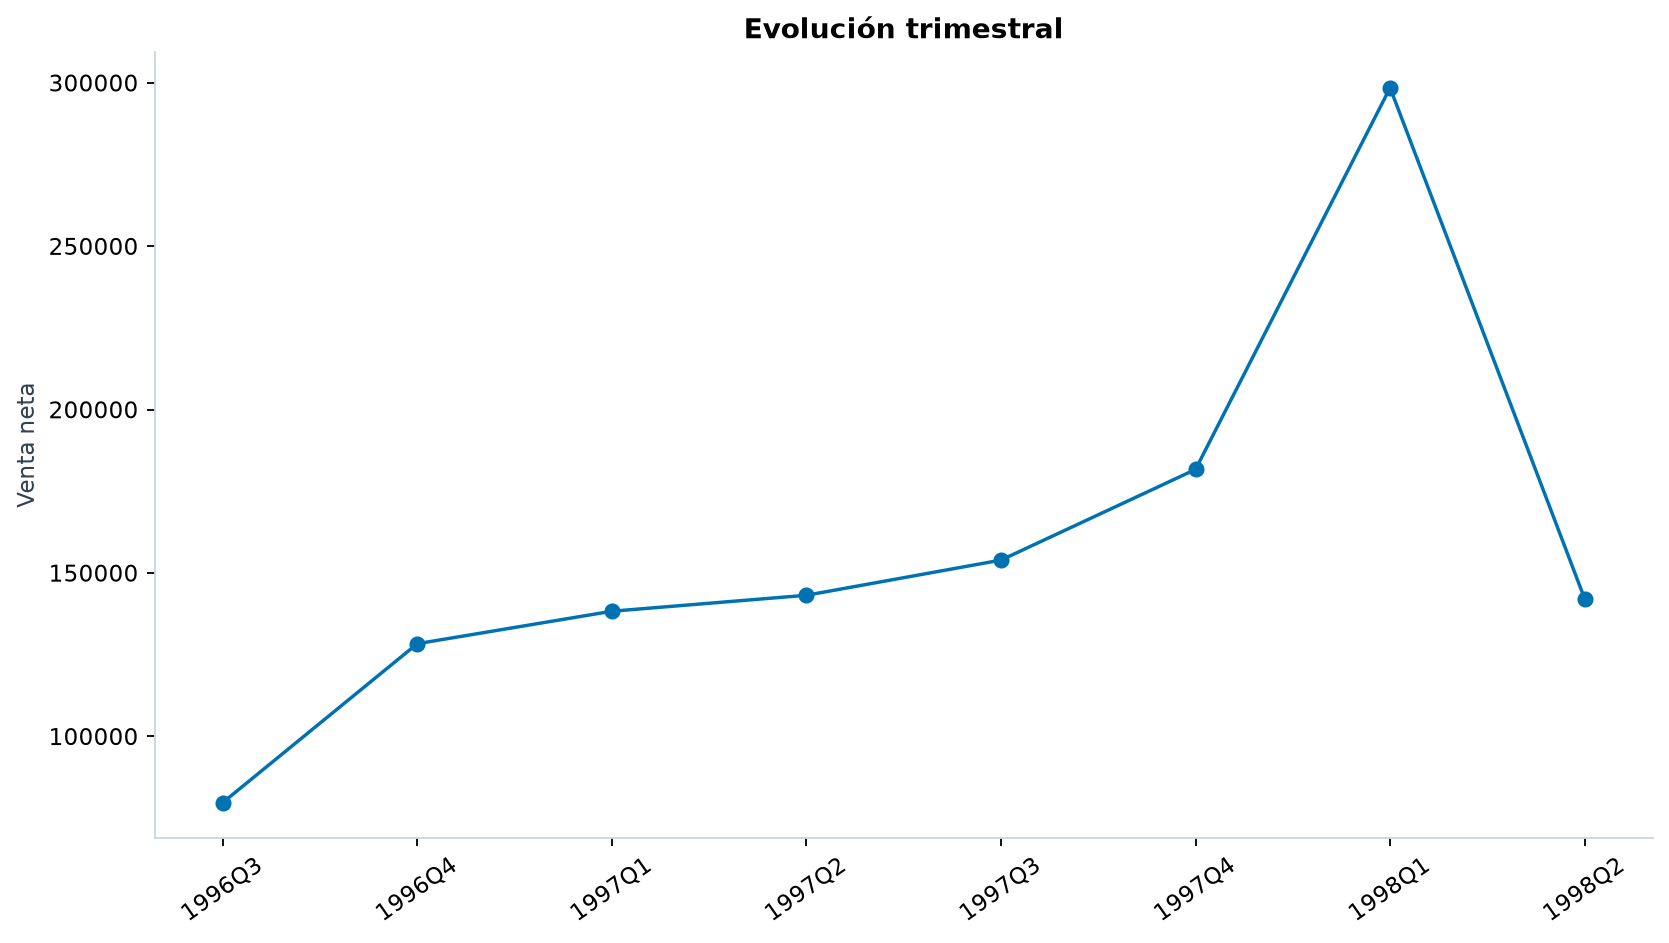

Resultado: El trimestre de mayor importe es 1998Q1, con 298,491.55.
Decisión: Comparar los trimestres completos de 1997 antes de utilizar la serie para presupuestar.
Límite: 1996-Q3 y 1998-Q2 tienen cobertura parcial. Una diferencia de duración impide compararlos directamente con trimestres completos.

N05 · Treemap de productos por categoría
Método: Cada área es proporcional a venta neta. Los productos se anidan en sus categorías; el dashboard permite abrir cada categoría.


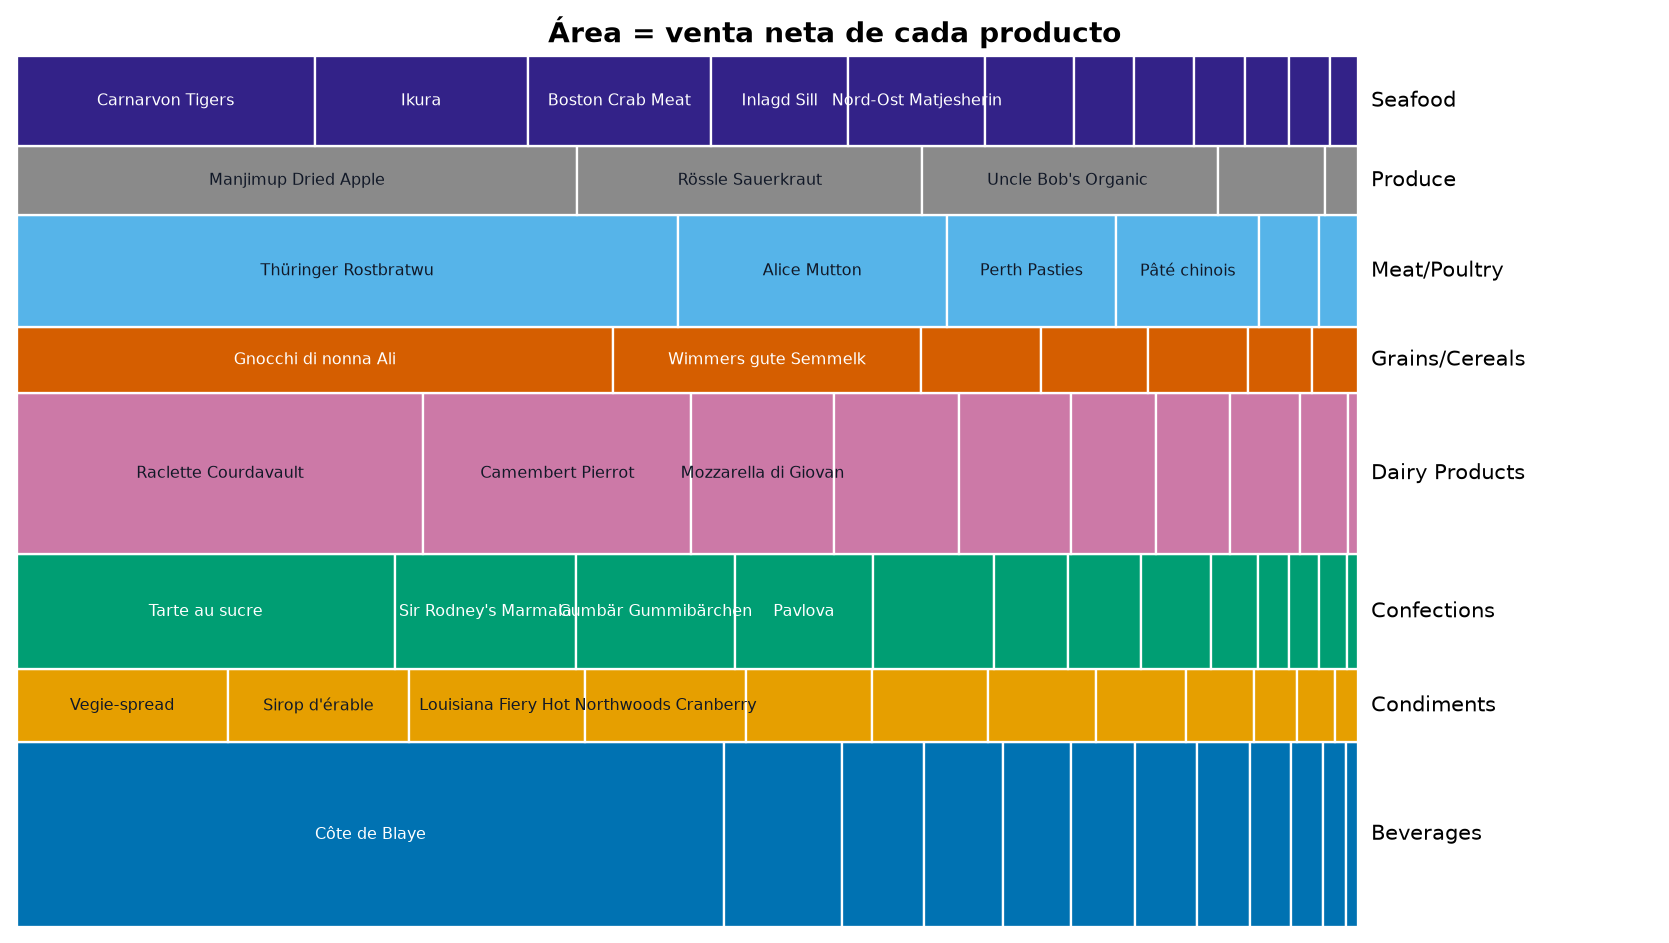

Resultado: Côte de Blaye aporta 141,396.73, el mayor importe de un producto de la muestra.
Decisión: Priorizar disponibilidad de productos de gran contribución y contrastar su margen cuando se disponga de costos.
Límite: La muestra no contiene costo de compra ni utilidad. Este gráfico mide contribución a ingresos y no rentabilidad.

N06 · Dispersión: descuento y cantidad
Método: Cada punto corresponde a una línea. Se calcula Pearson entre descuento fraccional y cantidad; los descuentos repetidos producen columnas de puntos.


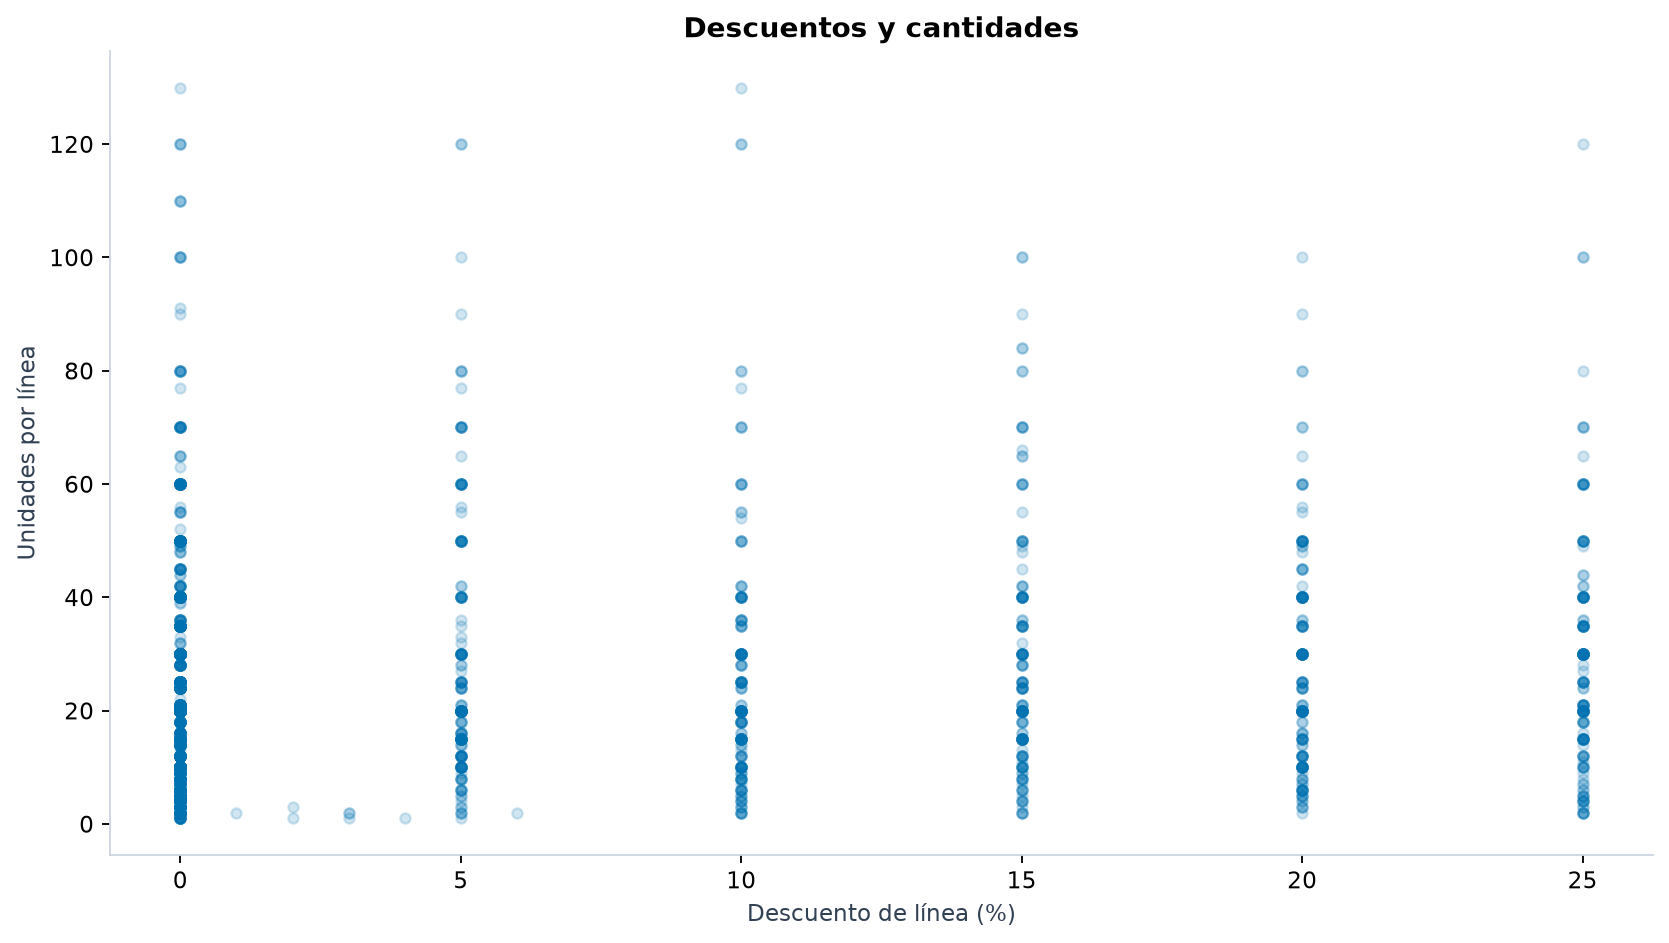

Resultado: La correlación observada es r = 0.129 en 2,155 líneas.
Decisión: Explorar descuentos por producto y cliente antes de evaluar una política promocional.
Límite: Una asociación no prueba que el descuento cause más ventas. Mezcla categorías, productos y condiciones de compra.

N07 · Distribución de países de clientes
Método: Se cuenta cada CustomerID del catálogo una vez. Los siete países con más clientes se muestran por separado y los demás se agrupan en Otros.


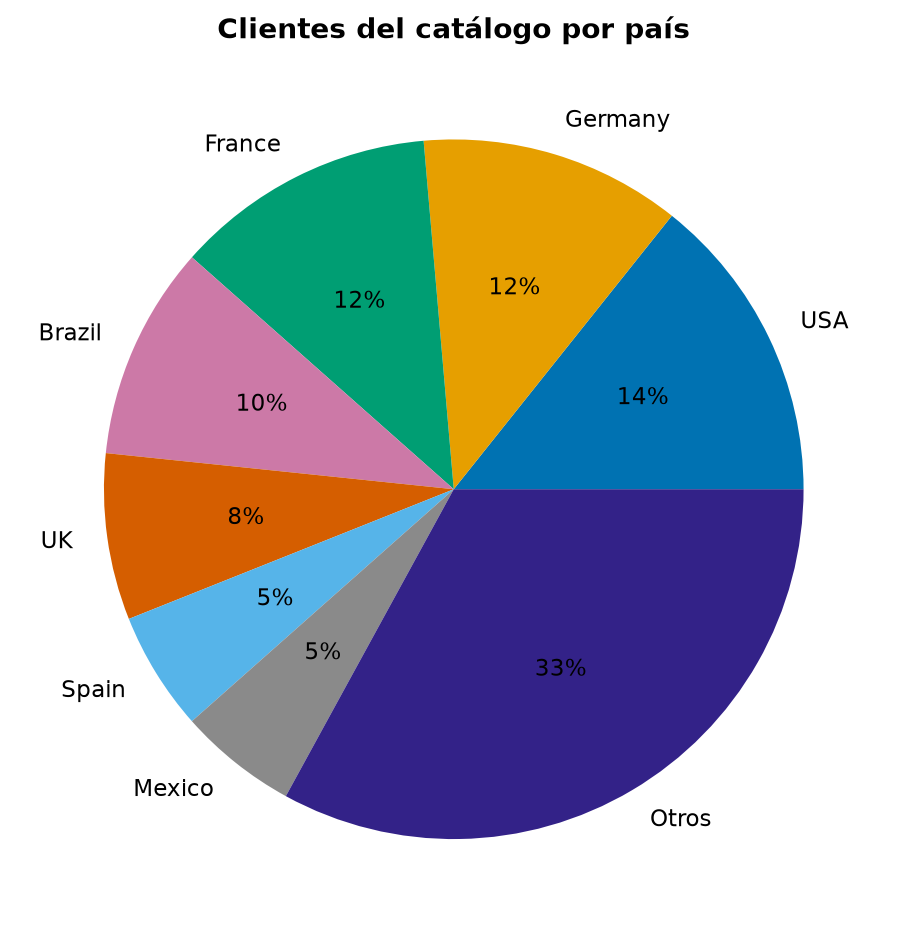

Resultado: Hay 91 clientes de 21 países. USA tiene 13 clientes (14.3%).
Decisión: Usar la distribución para contextualizar la cobertura comercial junto con importes de venta.
Límite: Representa clientes registrados; no población, participación de mercado ni clientes activos. Otros combina países distintos.

N08 · Box plot de precios por proveedor
Método: Se usa Products.UnitPrice, distinto del precio histórico de cada venta. Se eligen ocho proveedores por cantidad de productos y se muestran mediana, cuartiles y puntos extremos.


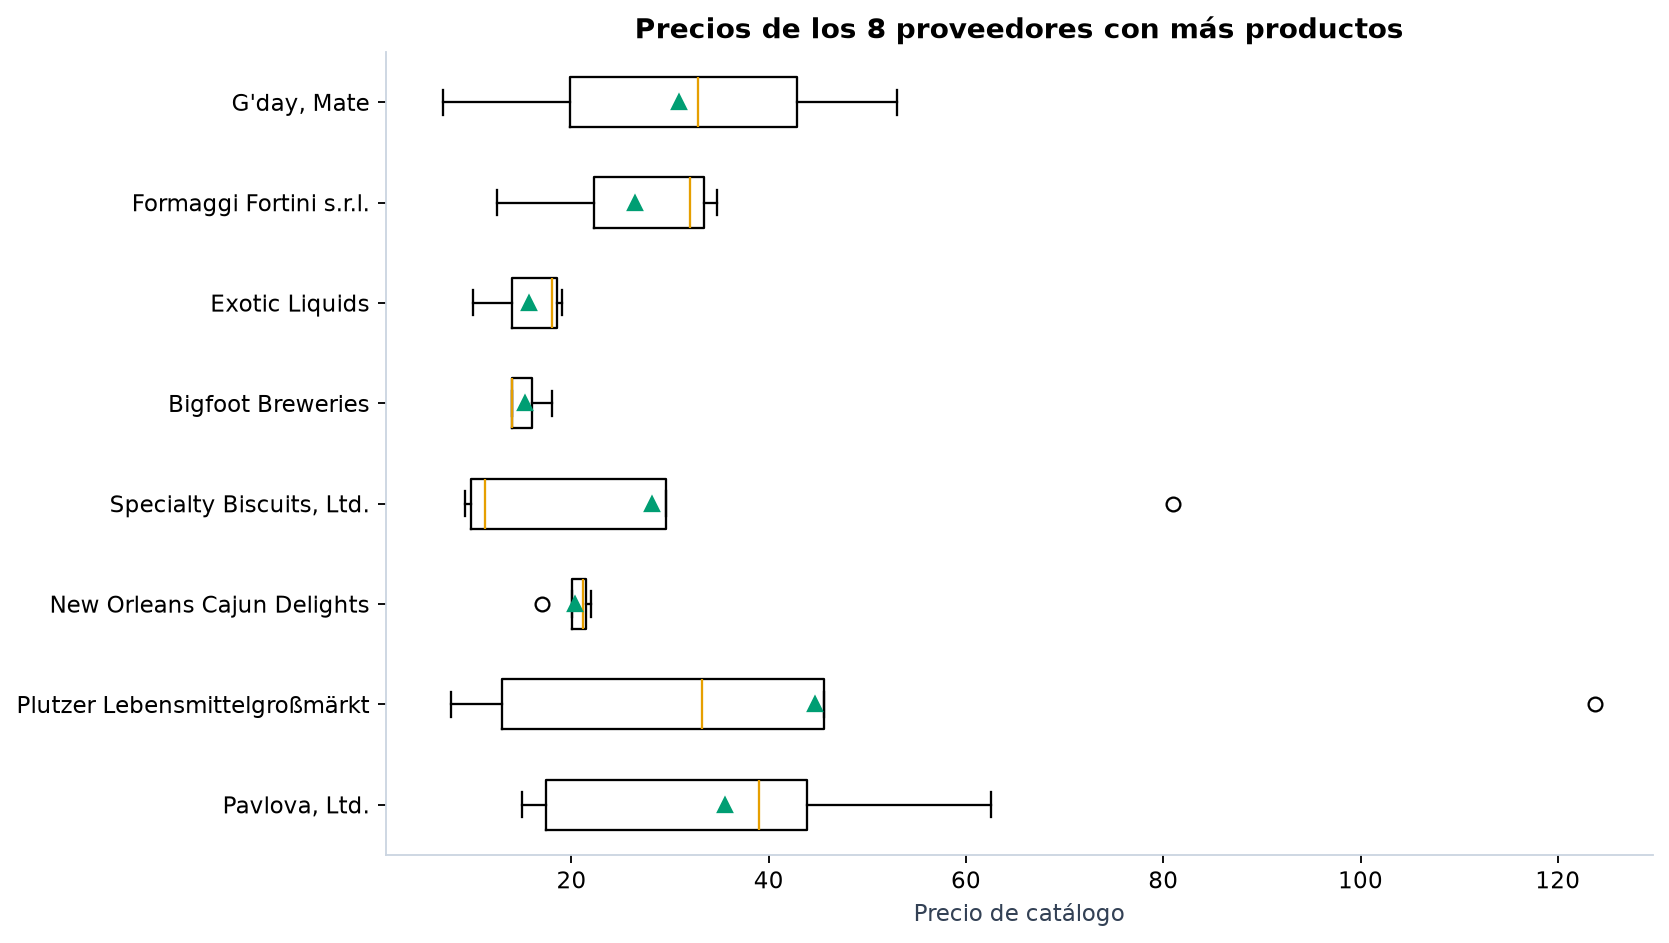

Resultado: El catálogo contiene 77 productos y 29 proveedores; el precio mediano es 19.50.
Decisión: Revisar proveedores con dispersión elevada para entender mezcla y posicionamiento del portafolio.
Límite: Las muestras por proveedor son pequeñas y las categorías difieren. Un precio extremo no es automáticamente un error.

N09 · Áreas: ventas acumuladas por empleado
Método: Se suman las ventas por empleado y mes, se completan celdas ausentes con cero y se aplica acumulado temporal. Las áreas se apilan; el valor individual es el espesor de cada banda.


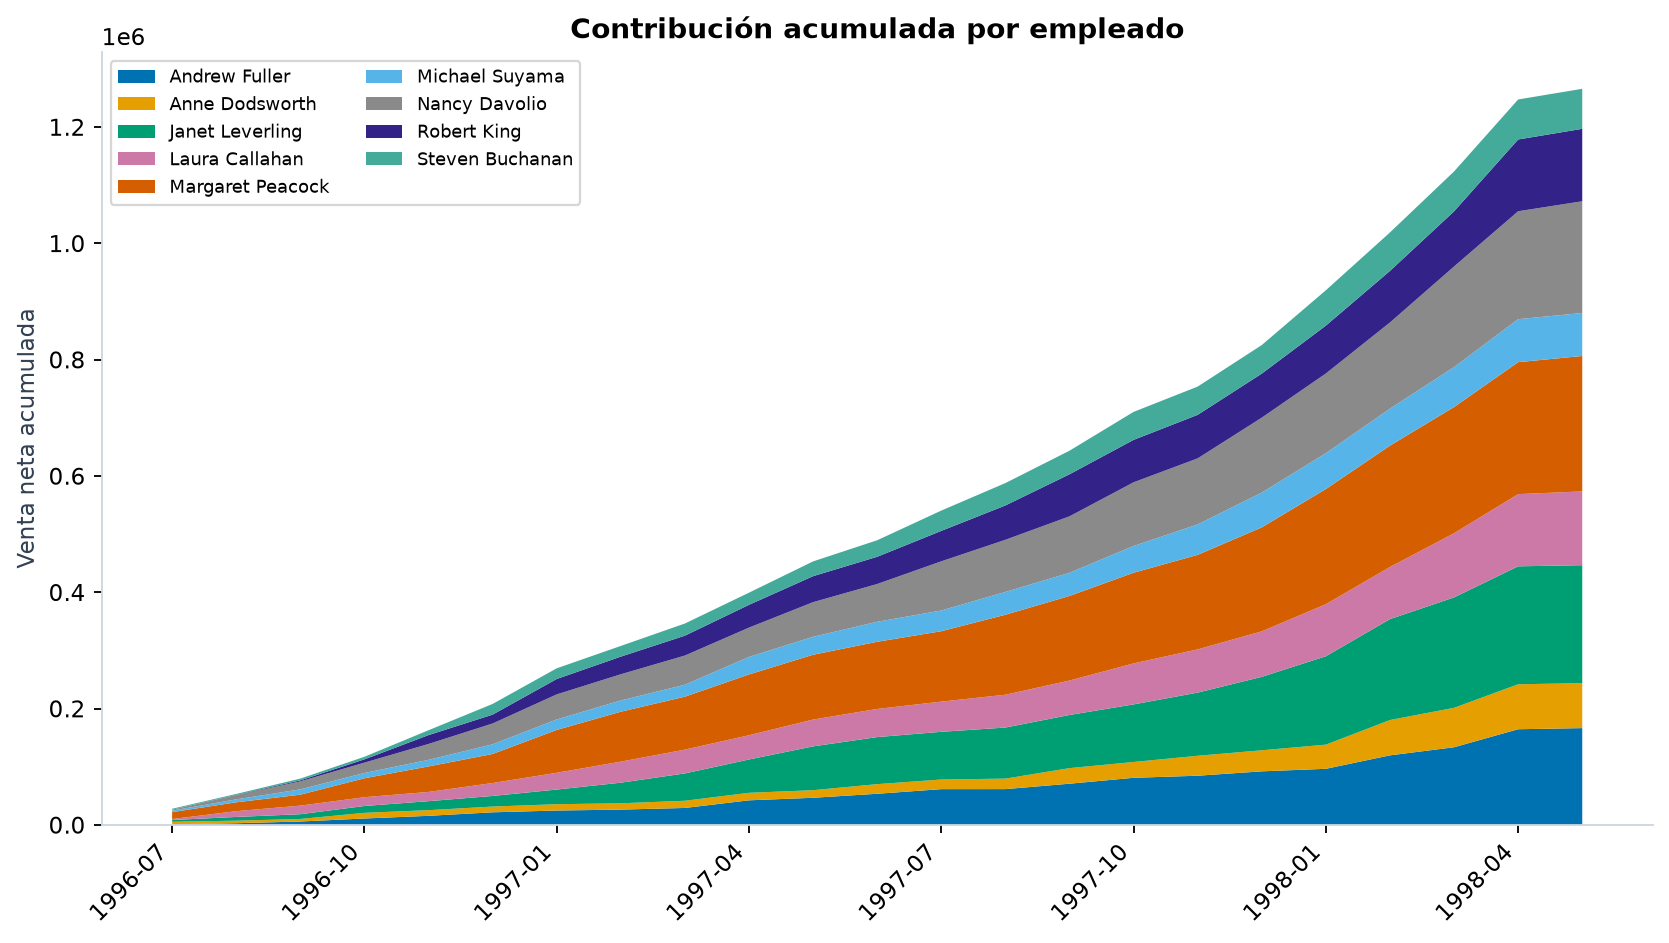

Resultado: Margaret Peacock registra 232,890.85, equivalente al 18.4% del importe neto.
Decisión: Combinar la contribución con número de pedidos, cartera asignada y metas para evaluar desempeño.
Límite: La posición superior de una banda no representa su valor individual. Las ventas no miden productividad ajustada por oportunidades.

N10 · Heatmap temporal de pedidos
Método: Se cuenta Orders.OrderID en la tabla de pedidos, una sola vez, por mes y día de semana. Se incluyen fines de semana con cero.


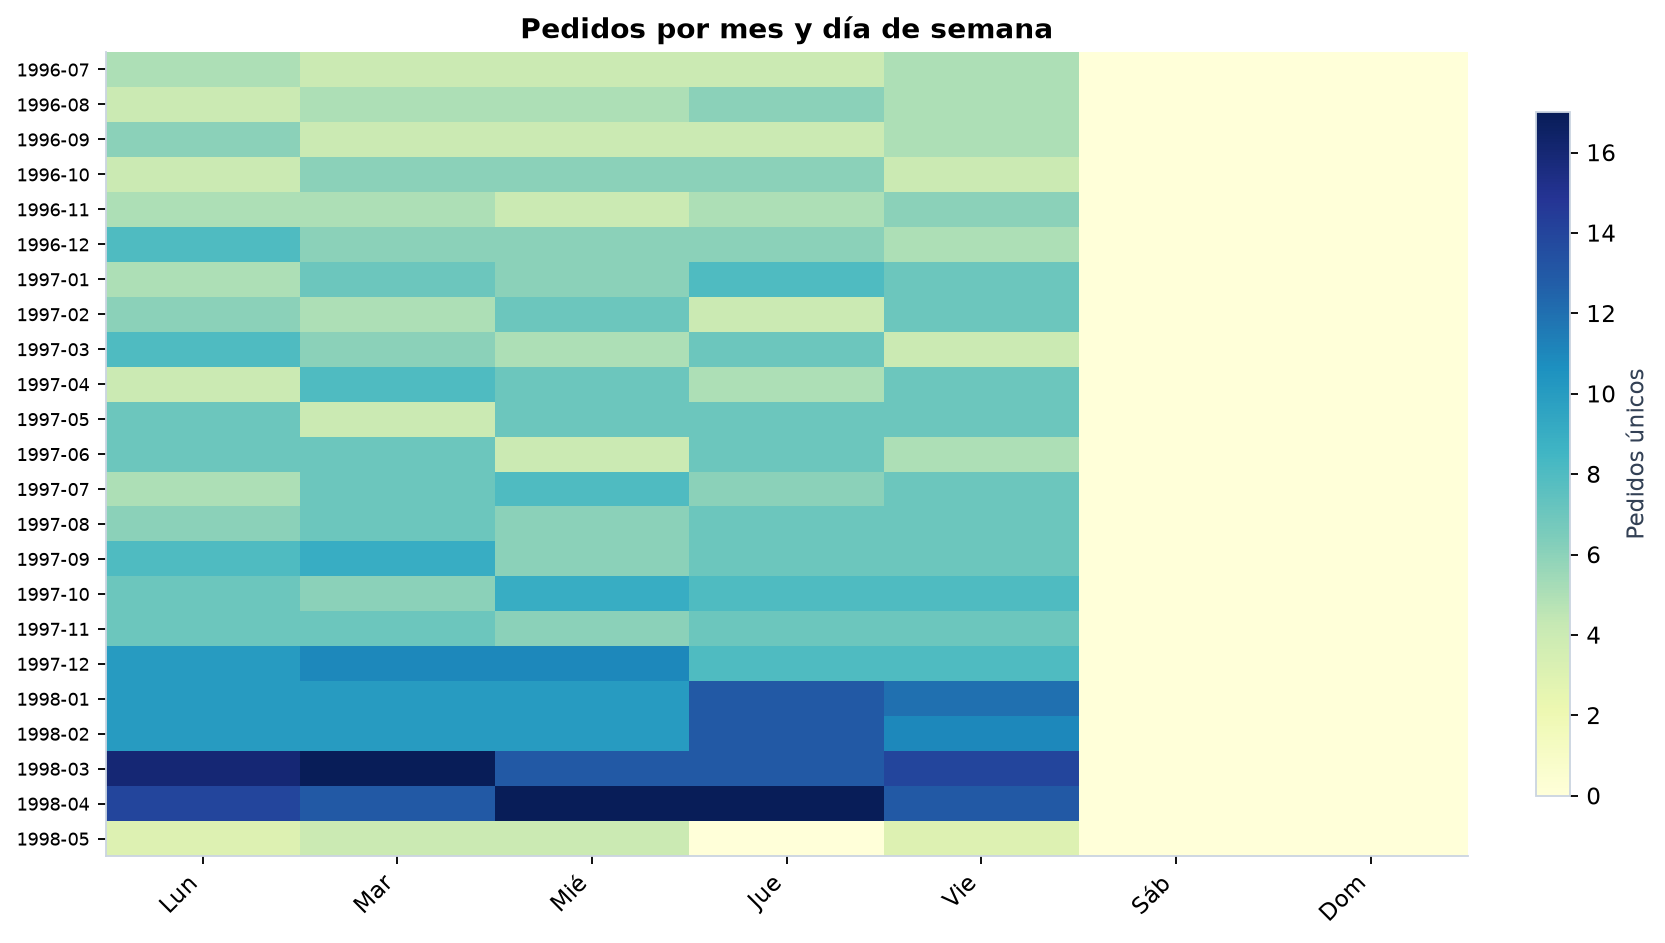

Resultado: Hay 830 pedidos únicos. Mar acumula 168 pedidos, el mayor conteo por día de semana.
Decisión: Planificar personal para los días con más actividad de registro, contrastando pedidos y tiempo de procesamiento.
Límite: El conteo agregado no ajusta por cuántas veces aparece cada día en cada mes. No representa hora de compra ni fecha de entrega.



In [4]:
meta = json.loads((root / 'docs/visualizaciones.json').read_text())
for item in [m for m in meta if m['id'].startswith('N')]:
    print(item['id'] + ' · ' + item['title'])
    print('Método:', item['method'])
    display(Image(filename=str(root / 'figuras' / (item['id'] + '.png')), width=900))
    print('Resultado:', item['insight'])
    print('Decisión:', item['decision'])
    print('Límite:', item['limit'])
    print()

## Oracle / HR

Cada figura se acompaña de método, resultado y límite. Los scripts de consulta están en `sql/` y `mongo/`.

H01 · Histograma salarial por departamento
Método: La versión estática superpone cuatro departamentos por tamaño. La versión interactiva permite mostrar u ocultar todos los departamentos desde la leyenda.


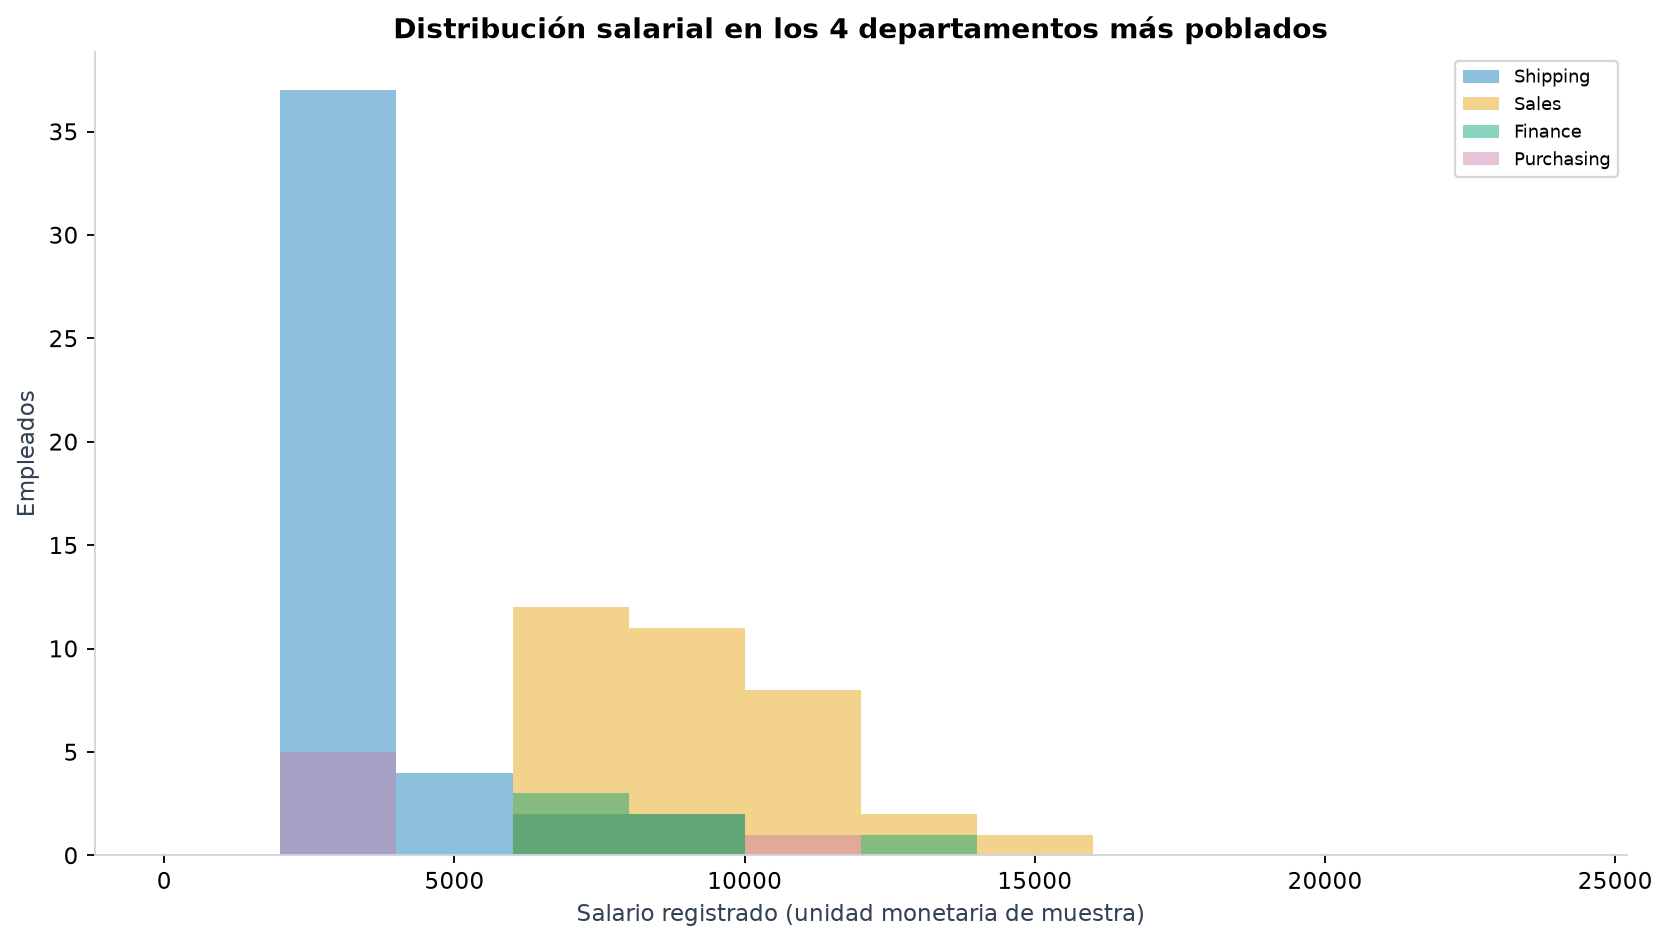

Resultado: Los 107 empleados tienen salario mediano 6,200.00, promedio 6,461.83 y máximo 24,000.00.
Decisión: Revisar bandas de compensación por puesto y departamento antes de explicar diferencias.
Límite: HR es una muestra académica. No documenta periodicidad ni moneda para este análisis; la dispersión no permite inferir discriminación o desempeño.

H02 · Radar de perfiles de puesto
Método: Se comparan cuatro puestos por tamaño. Salario medio, antigüedad media y plantilla se dividen por el máximo de cada variable en todos los puestos.


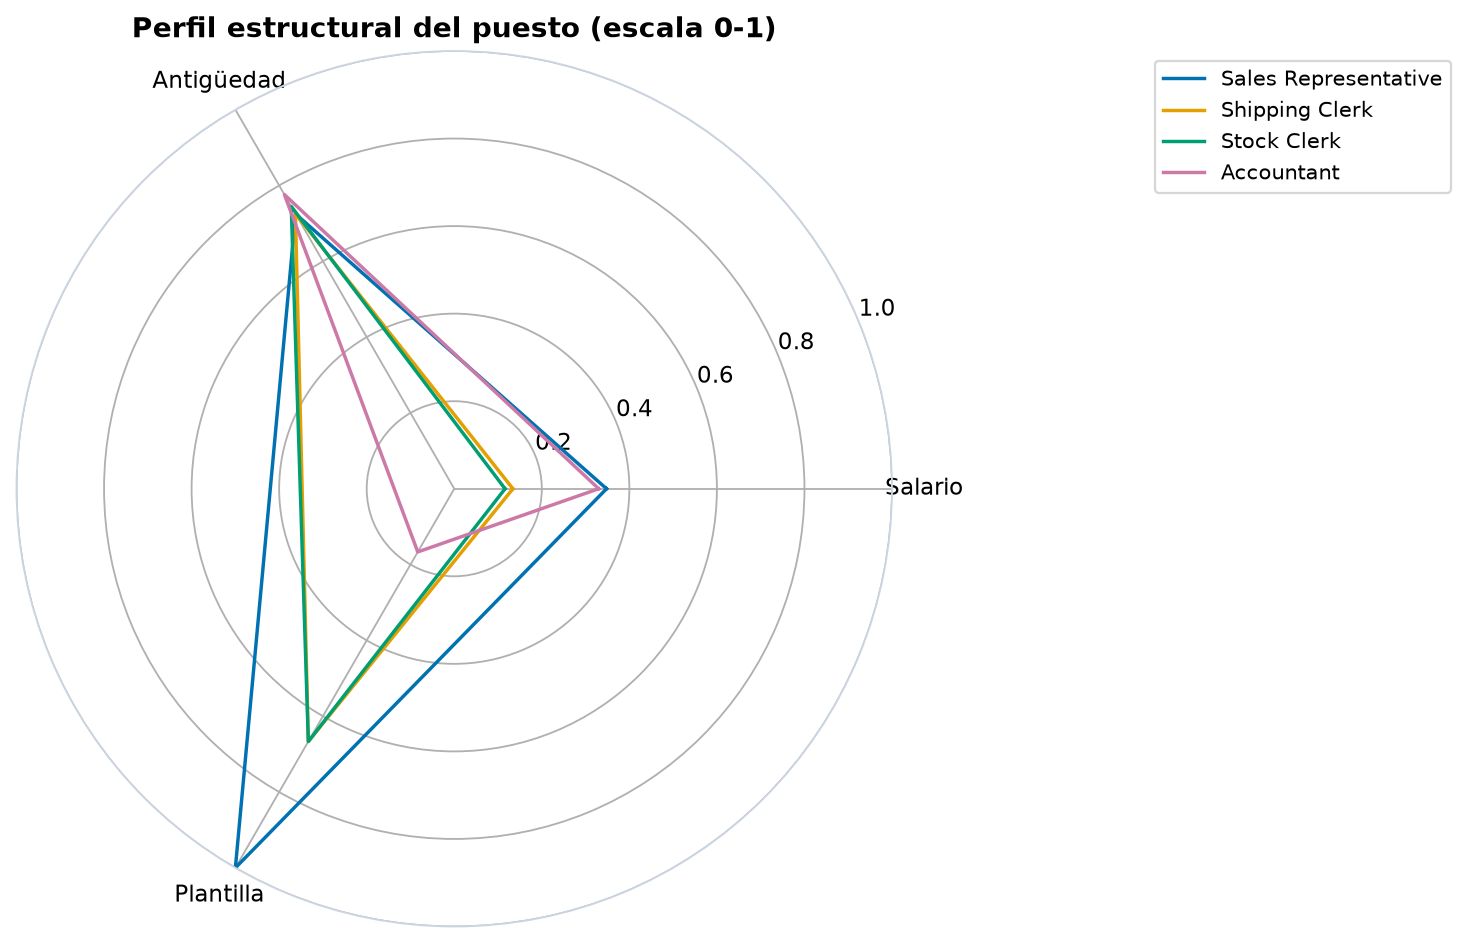

Resultado: Sales Representative es el puesto de mayor dotación entre los perfiles mostrados: 30 empleados.
Decisión: Comparar dimensiones organizacionales y utilizar hover para inspeccionar perfiles relativos.
Límite: No existen evaluaciones de competencias en HR. El radar es un perfil estructural y no mide habilidad, calidad de trabajo ni puntuación de desempeño.

H03 · Organigrama interactivo
Método: Se construye un árbol a partir de employee_id y manager_id. Se dibujan todos los empleados; el dashboard muestra nombre y puesto al pasar el cursor.


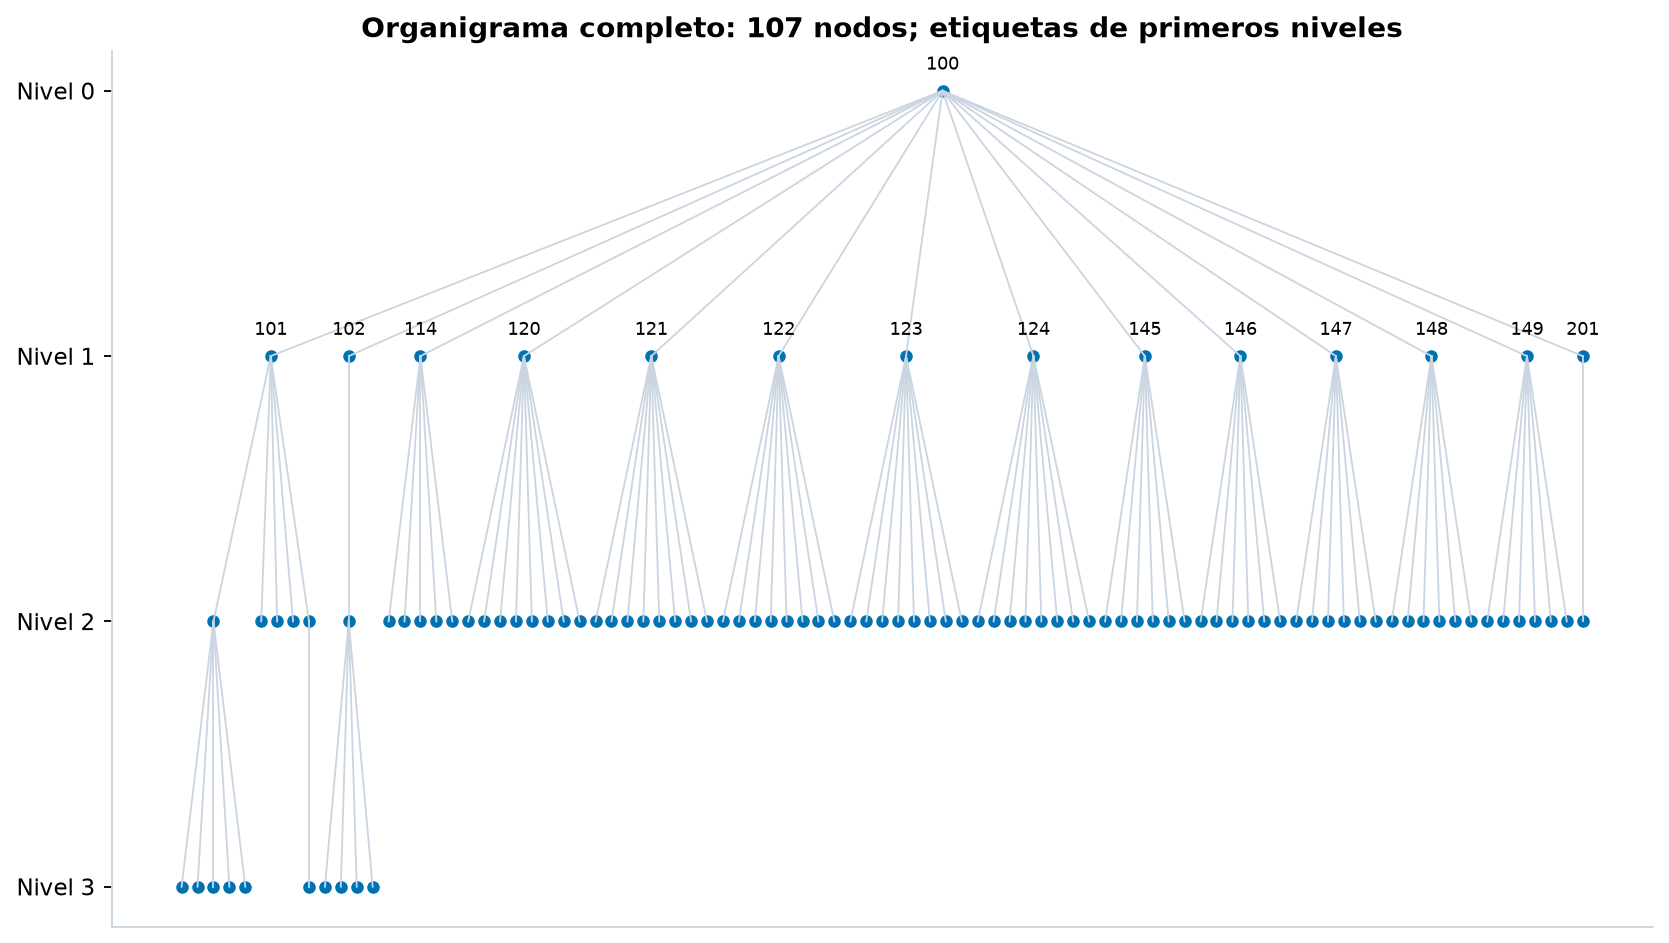

Resultado: La estructura contiene 107 nodos, 106 relaciones y 1 raíz. La profundidad máxima es 3 enlaces.
Decisión: Inspeccionar amplitud de supervisión y cadenas de reporte antes de proponer cambios de estructura.
Límite: Una relación jerárquica no indica carga de trabajo ni autoridad informal. La coordenada horizontal sólo separa ramas del árbol.

H04 · Mapa de calor de dotación por ubicación
Método: Se une employees con departments, locations, countries y regions mediante uniones izquierdas. Los empleados sin departamento conservan una categoría explícita.


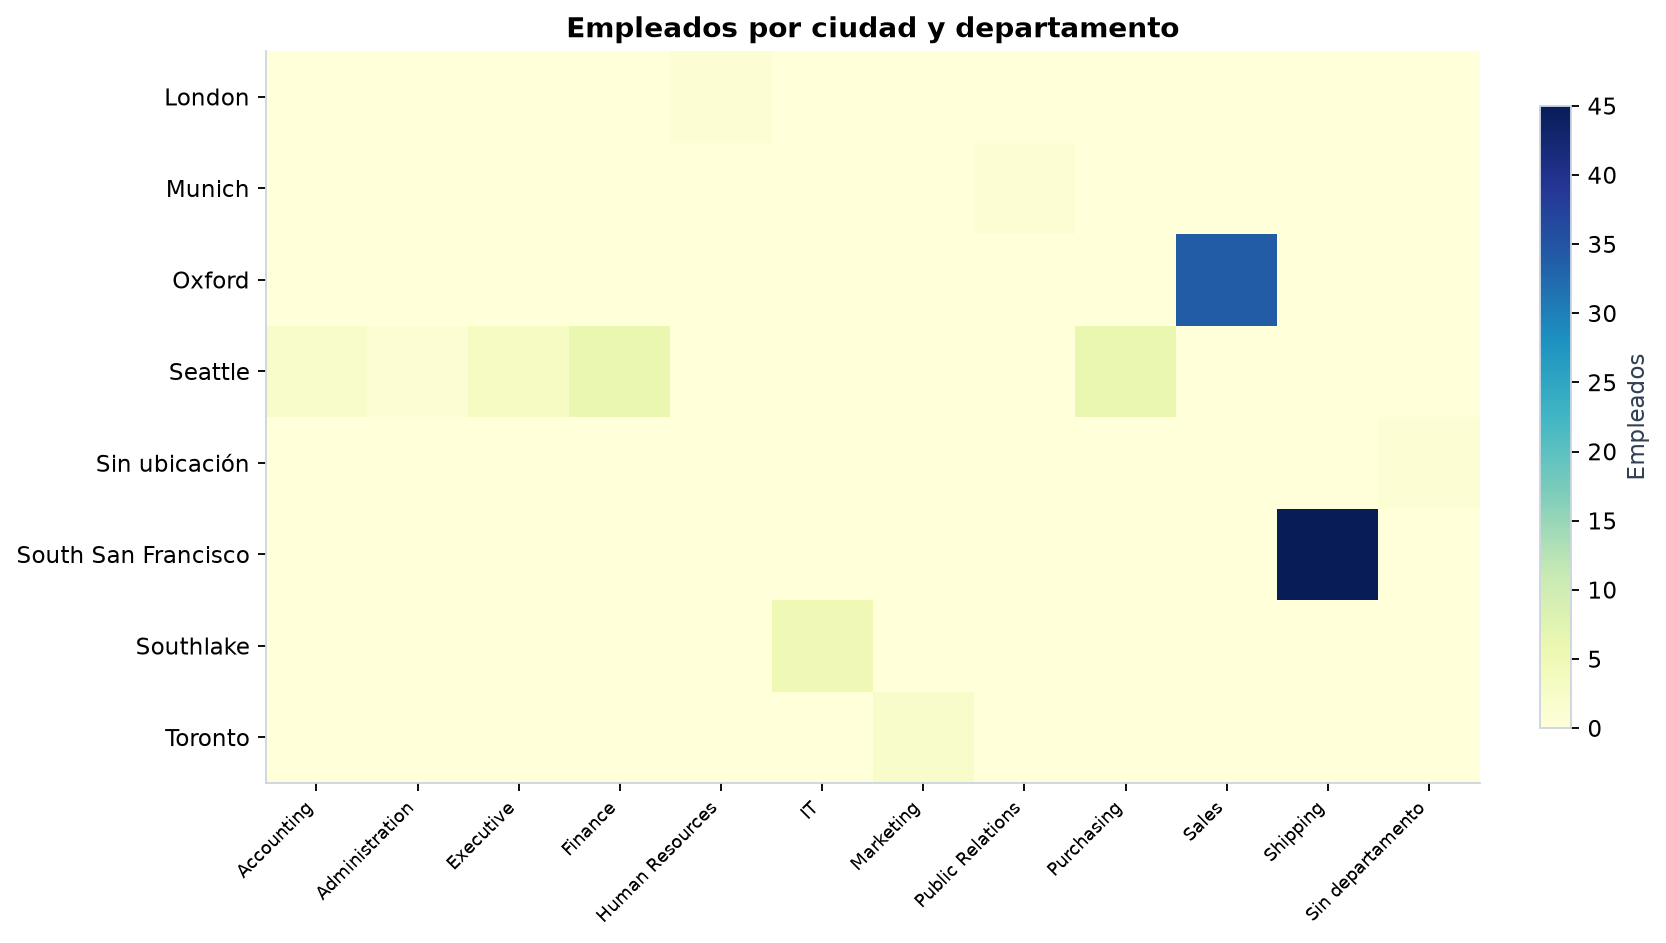

Resultado: South San Francisco concentra 45 empleados. Hay 1 empleado sin ubicación derivable.
Decisión: Identificar ubicaciones con concentración de personal y revisar registros sin asignación organizacional.
Límite: La densidad aquí es un conteo, no empleados por superficie. La ubicación corresponde al departamento y no al domicilio personal.

H05 · Violín salarial por antigüedad
Método: La antigüedad se calcula entre hire_date y 08/10/2026, en días / 365.25. Se crean tres bandas y se muestra una densidad estimada con mediana.


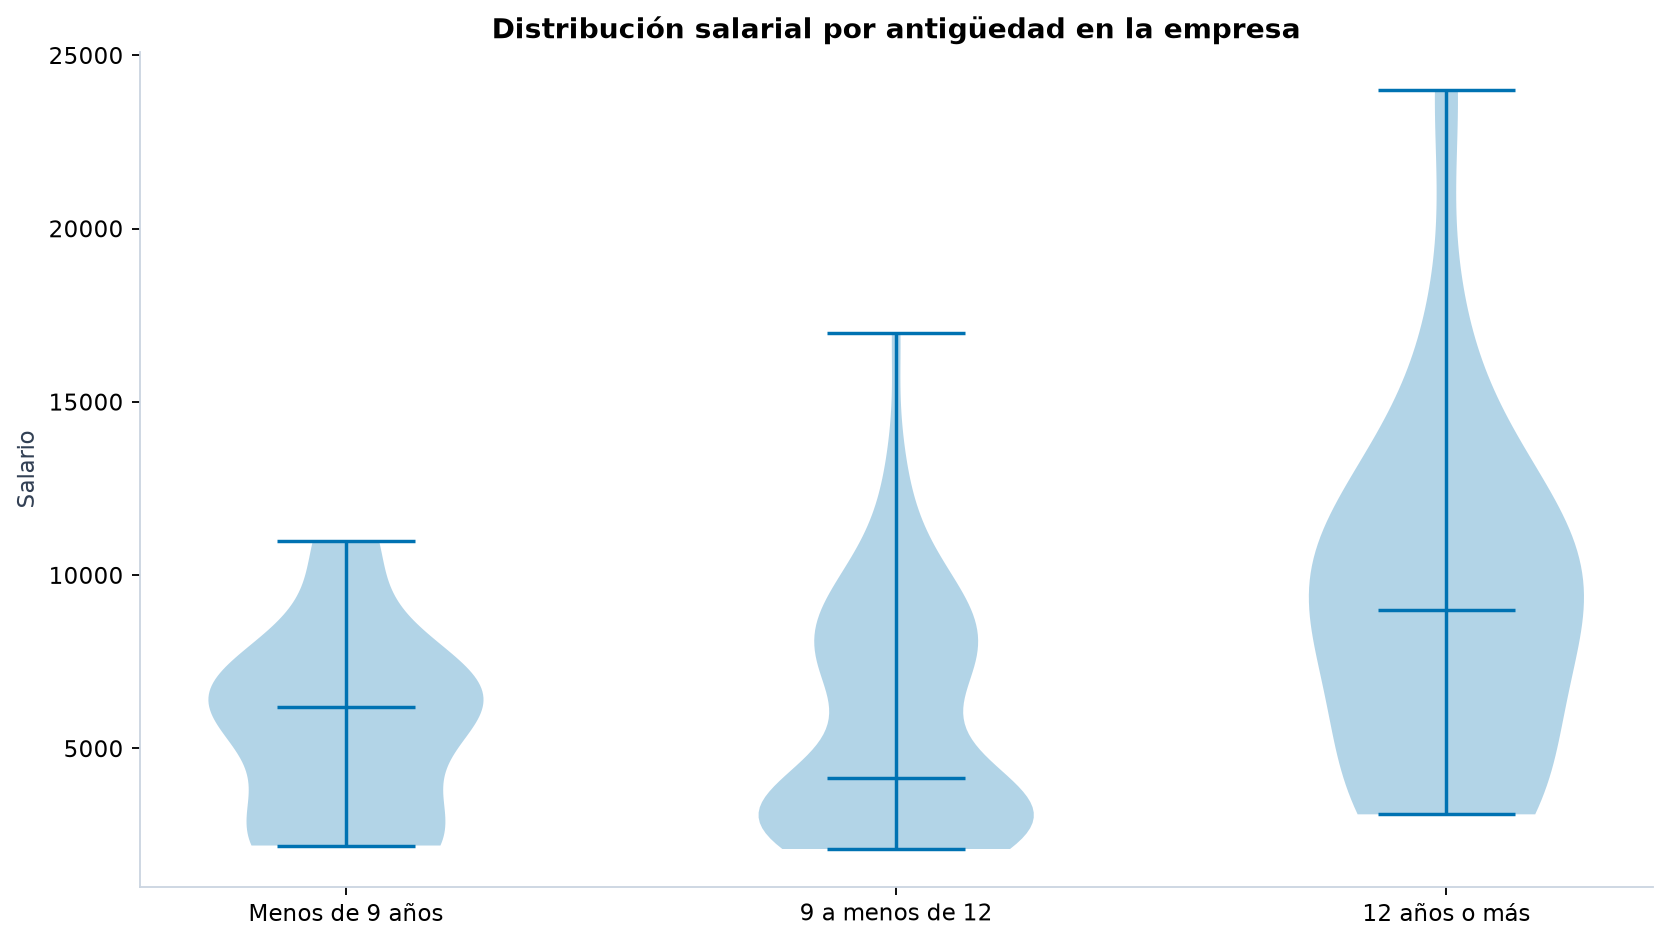

Resultado: La antigüedad mediana es 10.76 años. Las bandas contienen Menos de 9 años: 17, 9 a menos de 12: 66, 12 años o más: 24.
Decisión: Comparar salarios dentro del mismo puesto antes de interpretar el efecto de la antigüedad.
Límite: La antigüedad en la empresa no equivale a experiencia profesional total. La densidad depende de la muestra y del suavizado.

H06 · Sankey de cambios de departamento
Método: Por empleado se ordena job_history por start_date. Cada departamento se conecta con el siguiente registro y, al final, con el departamento actual. Los lados separan estado anterior y posterior.


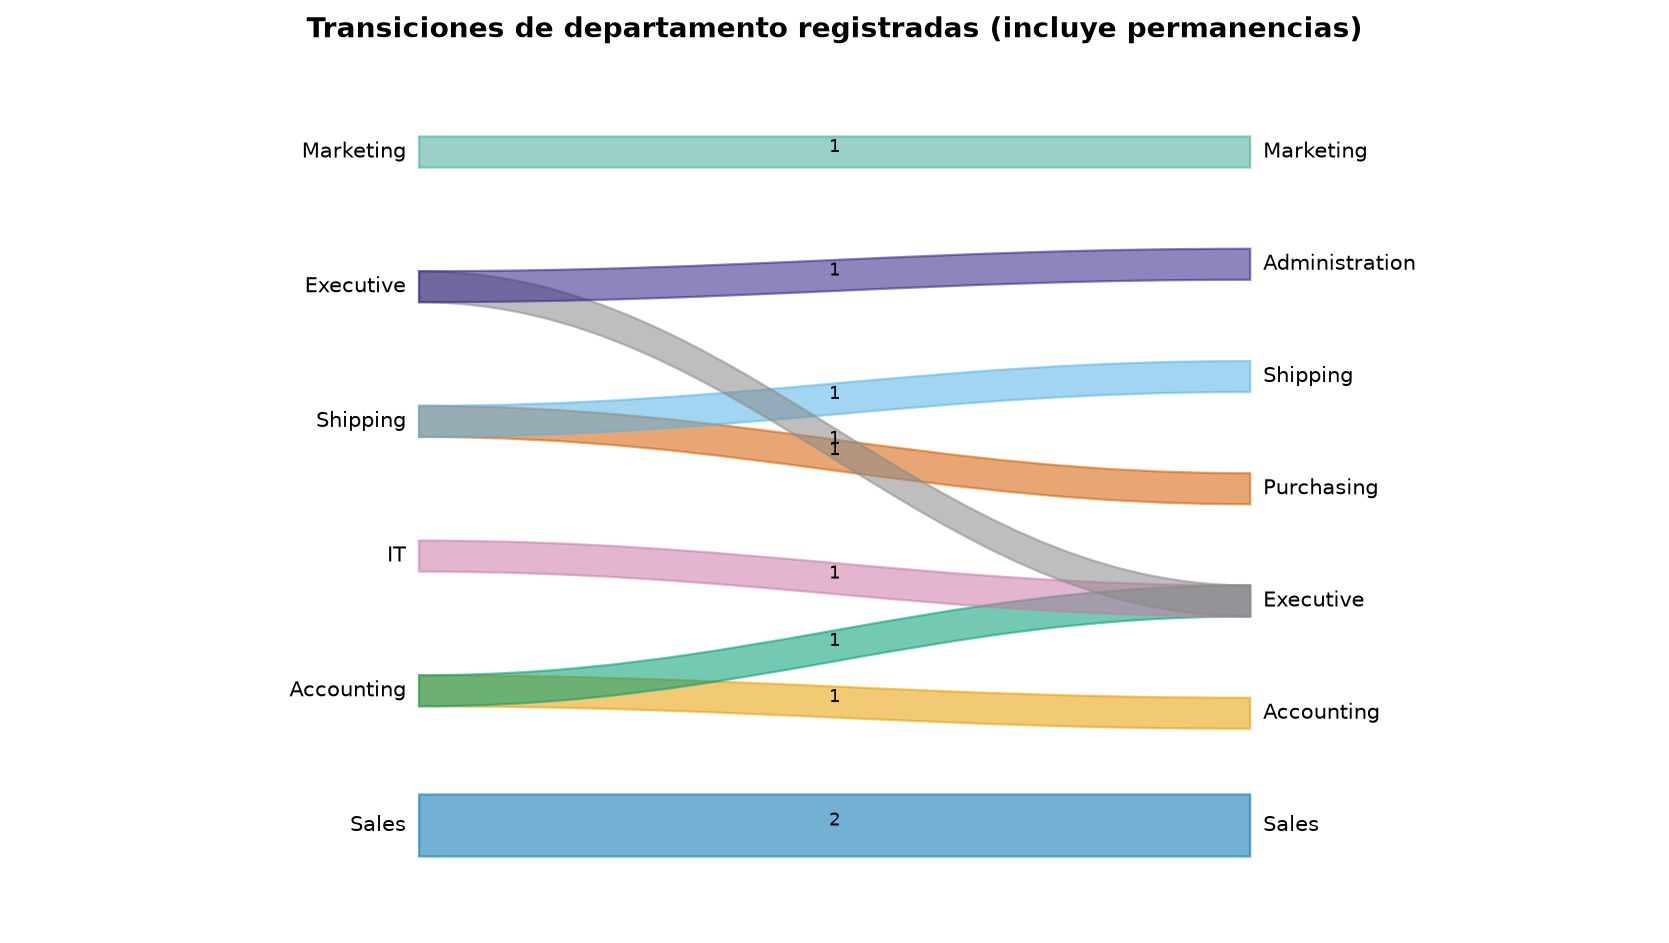

Resultado: Se reconstruyen 10 transiciones: 4 cambian de departamento y 6 permanecen en el mismo. El histórico contiene 7 empleados.
Decisión: Usar el flujo para formular preguntas sobre movilidad interna y cambios de puesto.
Límite: No existen bajas ni una población histórica completa. No se estima rotación de salida; un enlace al estado actual no documenta su fecha exacta.

H07 · Burbujas: salario y antigüedad
Método: Cada punto es un empleado. El área de burbuja representa tamaño del departamento; el color representa departamento. Las coordenadas son antigüedad y salario.


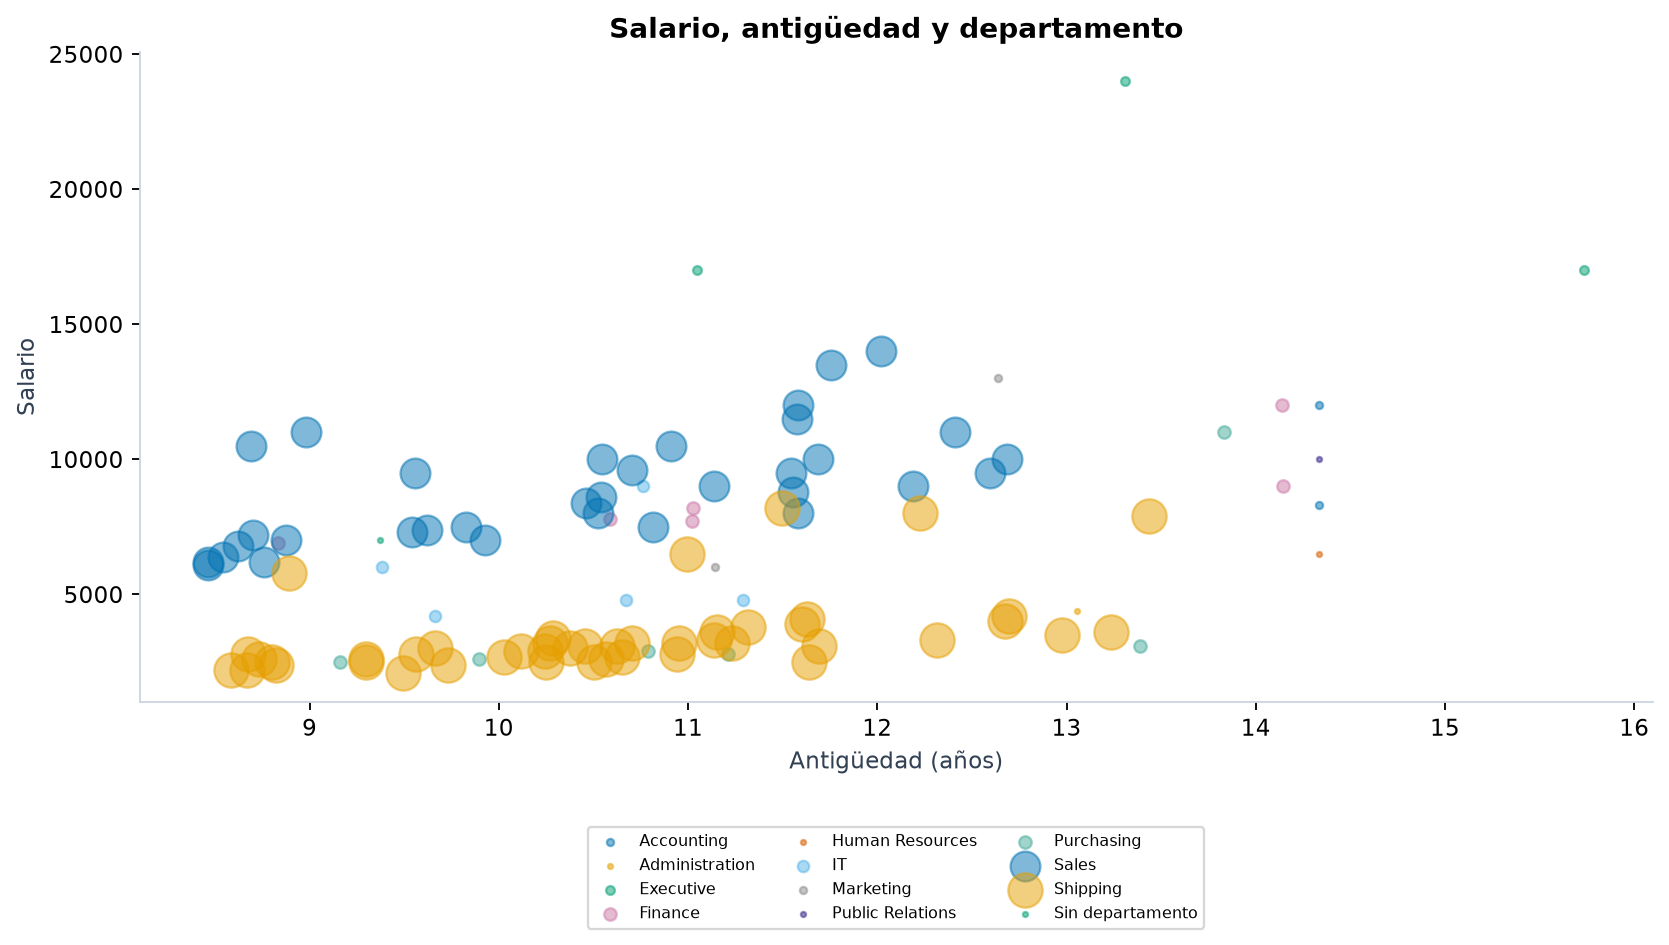

Resultado: La correlación de Pearson entre antigüedad y salario es 0.415.
Decisión: Examinar casos de compensación alta o baja dentro de grupos de puestos comparables.
Límite: El área repite el tamaño del departamento para cada empleado y no debe sumarse. La correlación está afectada por puesto, jerarquía y composición.

H08 · Densidad de contrataciones por mes
Método: Se combinan meses de contratación de todos los años. La curva aplica KDE con ancho relativo 0.25; es una aproximación suavizada de una variable discreta.


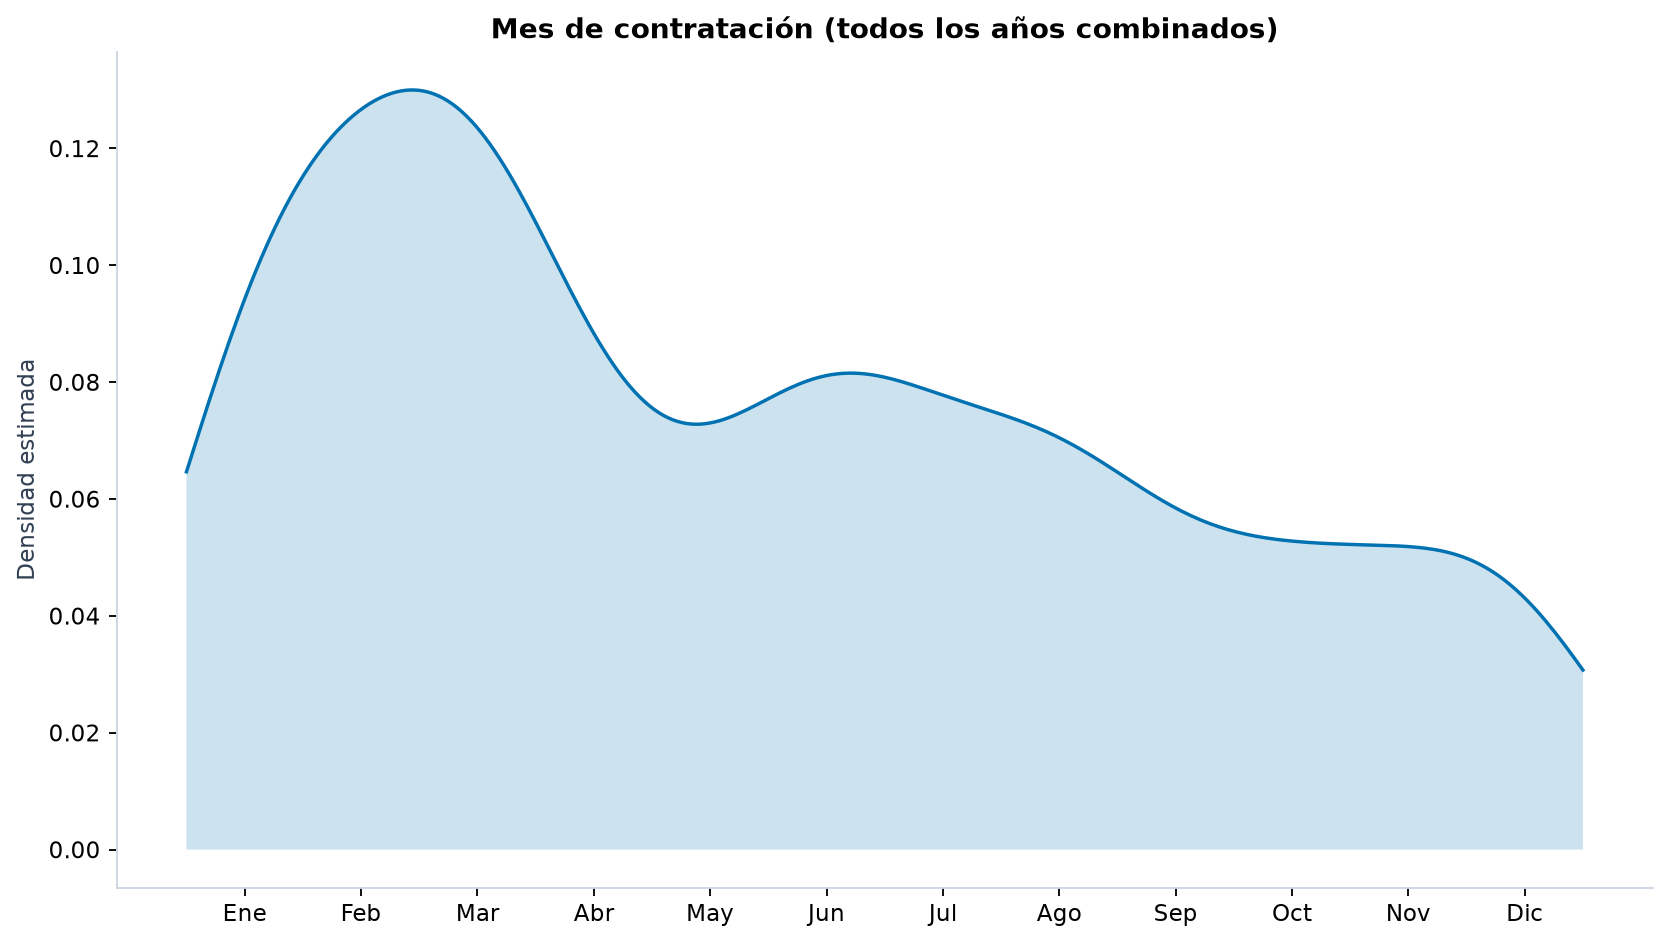

Resultado: El mes con más contrataciones observadas es 3, con 17 empleados del catálogo actual.
Decisión: Examinar el conteo por año y mes antes de atribuir estacionalidad al proceso de contratación.
Límite: Enero y diciembre son adyacentes en un calendario, pero esta KDE no es circular. Sólo incluye empleados actuales y no permite estimar tasa histórica de contratación.

H09 · Donut de empleados por región
Método: Cada empleado se asigna a la región de su departamento mediante la cadena de ubicaciones. Se conserva Sin región para el registro sin departamento.


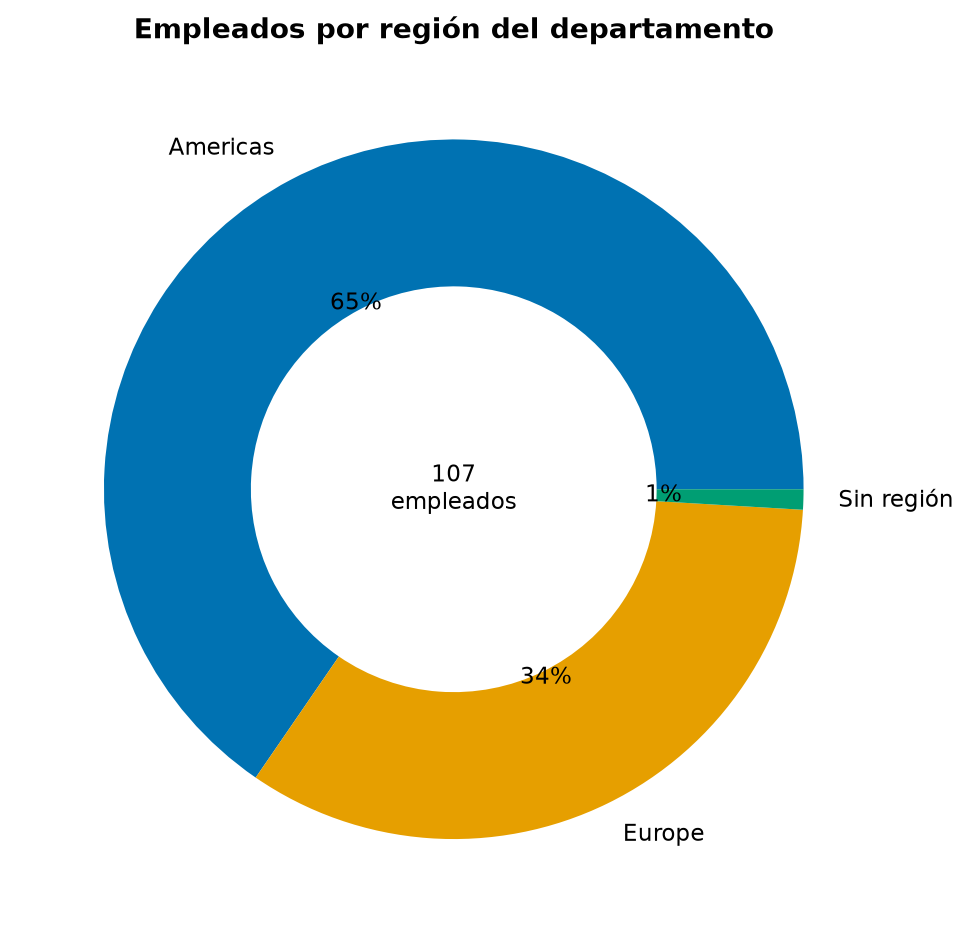

Resultado: Americas concentra 70 de 107 empleados (65.4%).
Decisión: Evaluar concentración territorial del catálogo organizacional y calidad de asignaciones.
Límite: La región es una categoría geográfica corporativa de esta versión de HR. No aporta nacionalidad, edad, sexo ni otras variables demográficas personales.

H10 · Waterfall de bandas salariales: escenario ilustrativo
Método: Se encadenan el mínimo y máximo de IT_PROG y los máximos de AD_VP y AD_PRES. Cada escalón representa diferencia entre límites de bandas definidos en jobs.


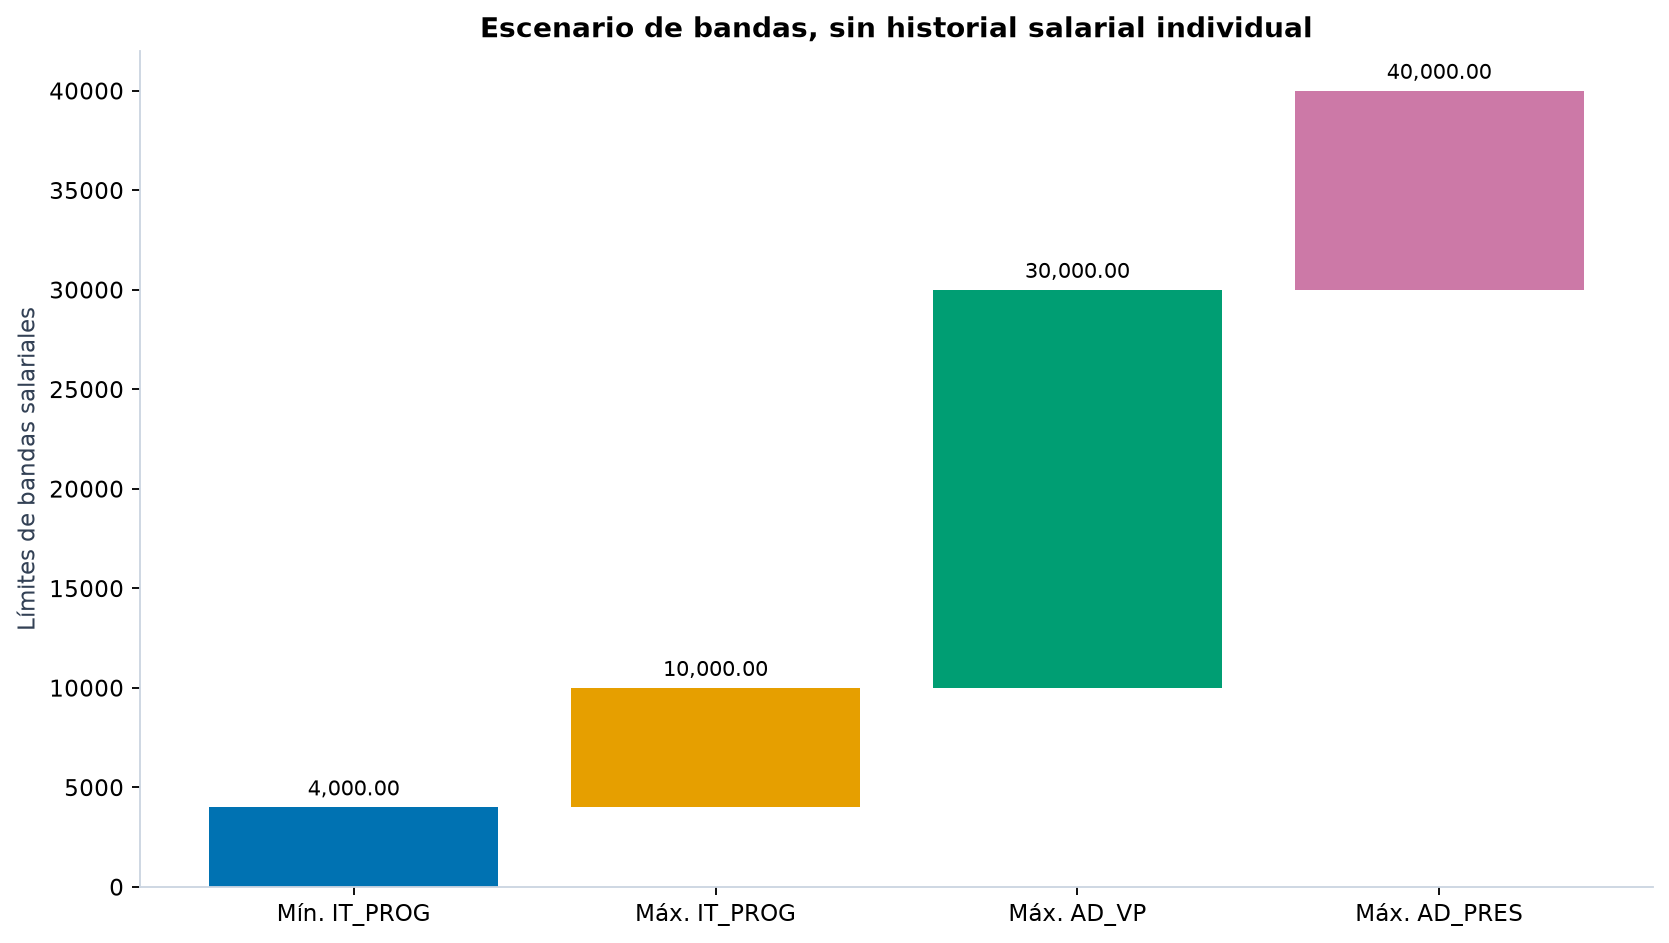

Resultado: El escenario va de 4,000.00 a 40,000.00; la diferencia es 36,000.00.
Decisión: Ilustrar cómo se comparan bandas de puestos; reemplazarlo por un historial real si se desea analizar progresión de una carrera.
Límite: No representa ascensos observados, salarios pasados ni trayectoria de un empleado. La secuencia de puestos es hipotética y las bandas son datos oficiales.



In [5]:
meta = json.loads((root / 'docs/visualizaciones.json').read_text())
for item in [m for m in meta if m['id'].startswith('H')]:
    print(item['id'] + ' · ' + item['title'])
    print('Método:', item['method'])
    display(Image(filename=str(root / 'figuras' / (item['id'] + '.png')), width=900))
    print('Resultado:', item['insight'])
    print('Decisión:', item['decision'])
    print('Límite:', item['limit'])
    print()

## MongoDB / sensores sintéticos

Cada figura se acompaña de método, resultado y límite. Los scripts de consulta están en `sql/` y `mongo/`.

S01 · Serie temporal de temperatura por ciudad
Método: Se promedian dos estaciones y 24 lecturas horarias por día y ciudad. La fecha se obtiene después de convertir UTC a America/Santo_Domingo.


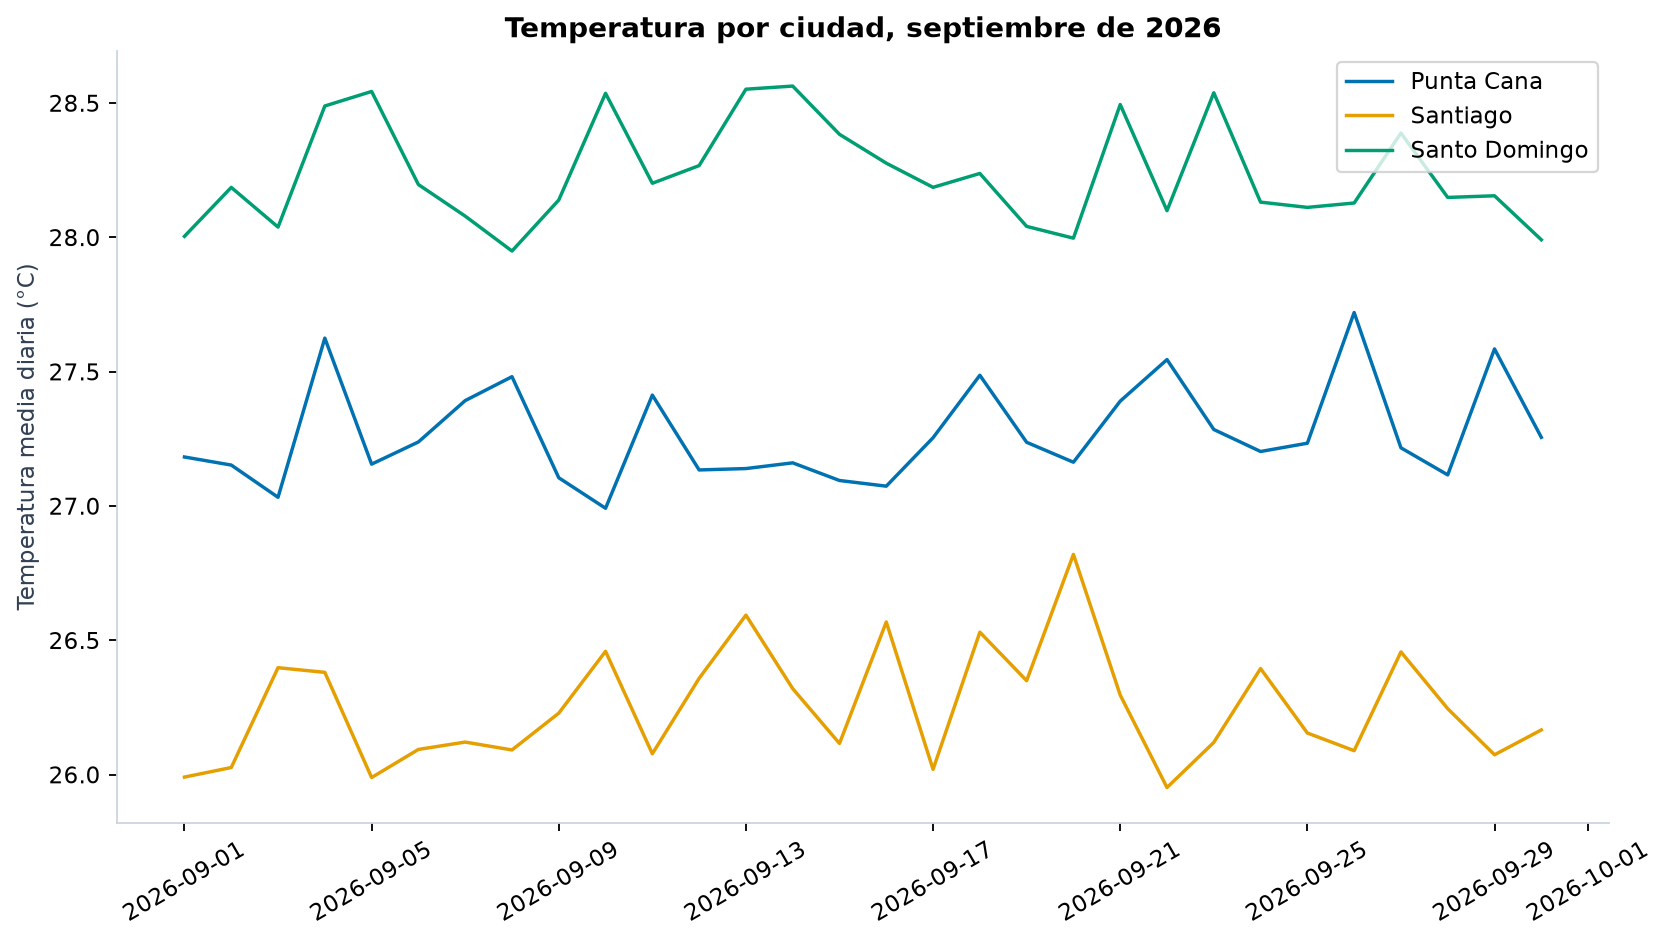

Resultado: Santo Domingo tiene la mayor temperatura media: 28.24 °C.
Decisión: Inspeccionar cambios diarios y confirmar si responden a señales persistentes o a puntos anómalos.
Límite: Todas las lecturas son sintéticas; las diferencias entre ciudades se definieron en el generador y no describen el clima real.

S02 · Mapa de calor geográfico de lecturas
Método: Se agregan lecturas por coordenada de estación. La figura estática ubica puntos coloreados en latitud/longitud; el dashboard ofrece una densidad geográfica sin mapa externo.


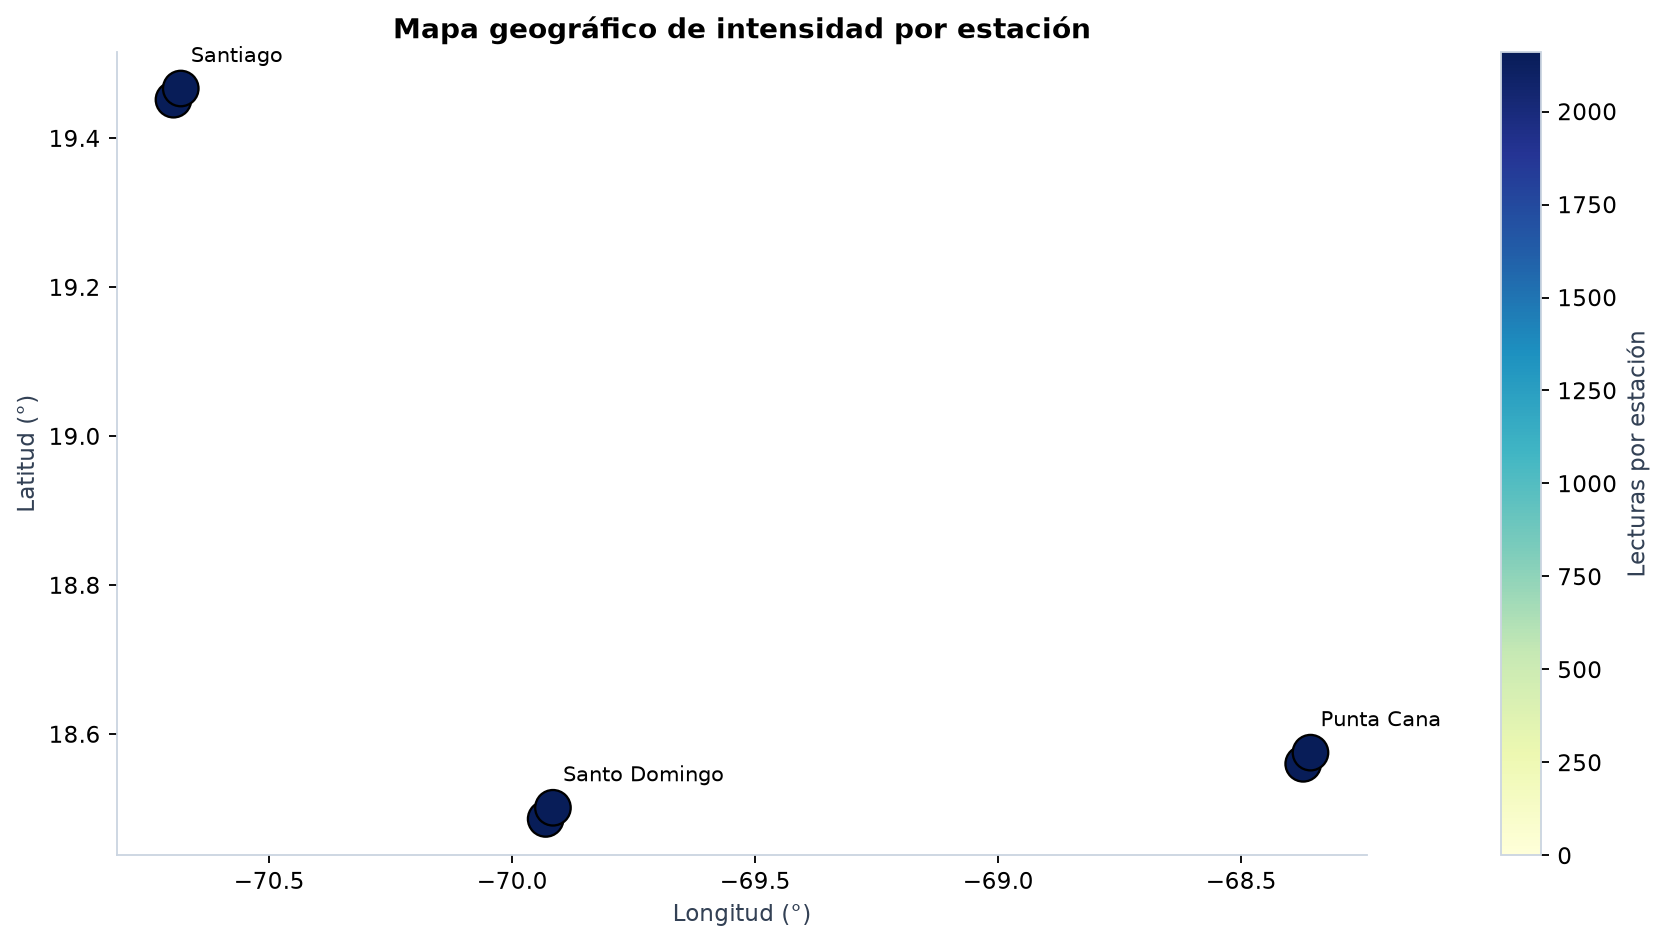

Resultado: Las seis estaciones tienen 2,160 lecturas cada una; la cobertura de observación es uniforme.
Decisión: Utilizar el mapa para reconocer distribución de estaciones y revisar diferencias de cobertura cuando se incorporen datos reales.
Límite: El mapa representa conteo y no temperatura. Las coordenadas de estaciones son ilustrativas; no corresponden a instalaciones verificadas.

S03 · Violines por tipo de sensor
Método: Se dibujan tres distribuciones en paneles con escalas y unidades independientes. Las colas incluyen anomalías inyectadas.


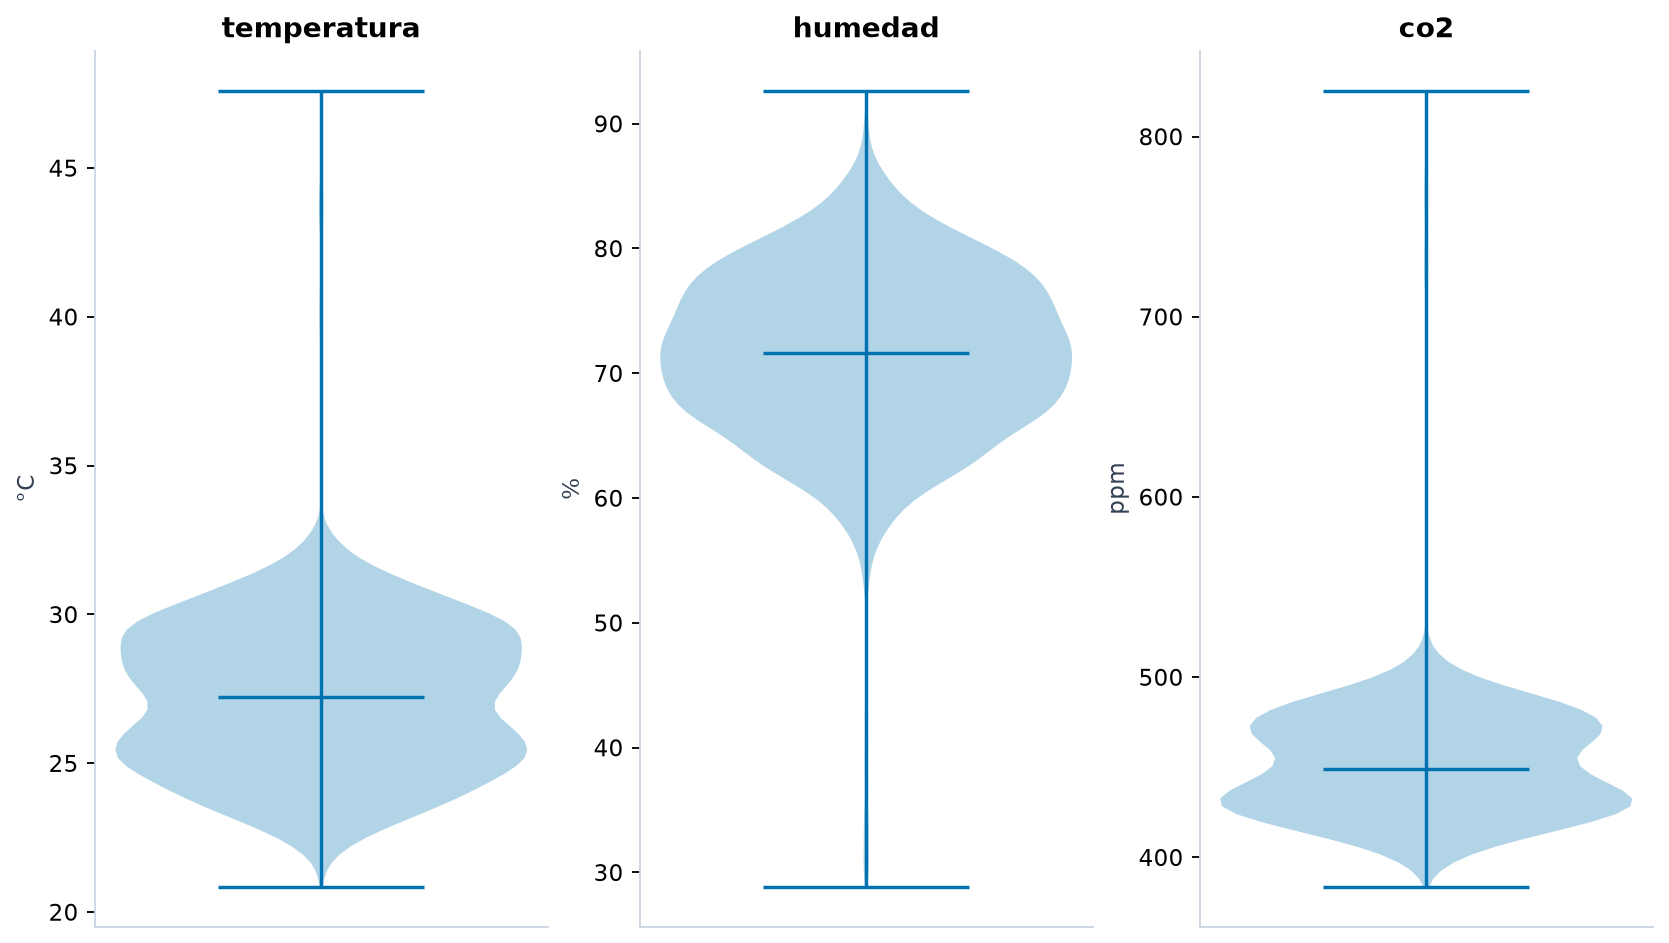

Resultado: Las medianas son temperatura 27.23 °C, humedad 71.64% y CO2 449.10 ppm.
Decisión: Comparar dispersión dentro de cada magnitud y revisar extremos con el detector robusto.
Límite: Las variables tienen unidades distintas. Las alturas entre paneles no deben compararse; la forma depende del ancho de suavizado.

S04 · Matriz de dispersión entre sensores
Método: Se alinea cada estación y timestamp antes de pivotar tipos. No se correlacionan listas de lecturas sin correspondencia temporal.


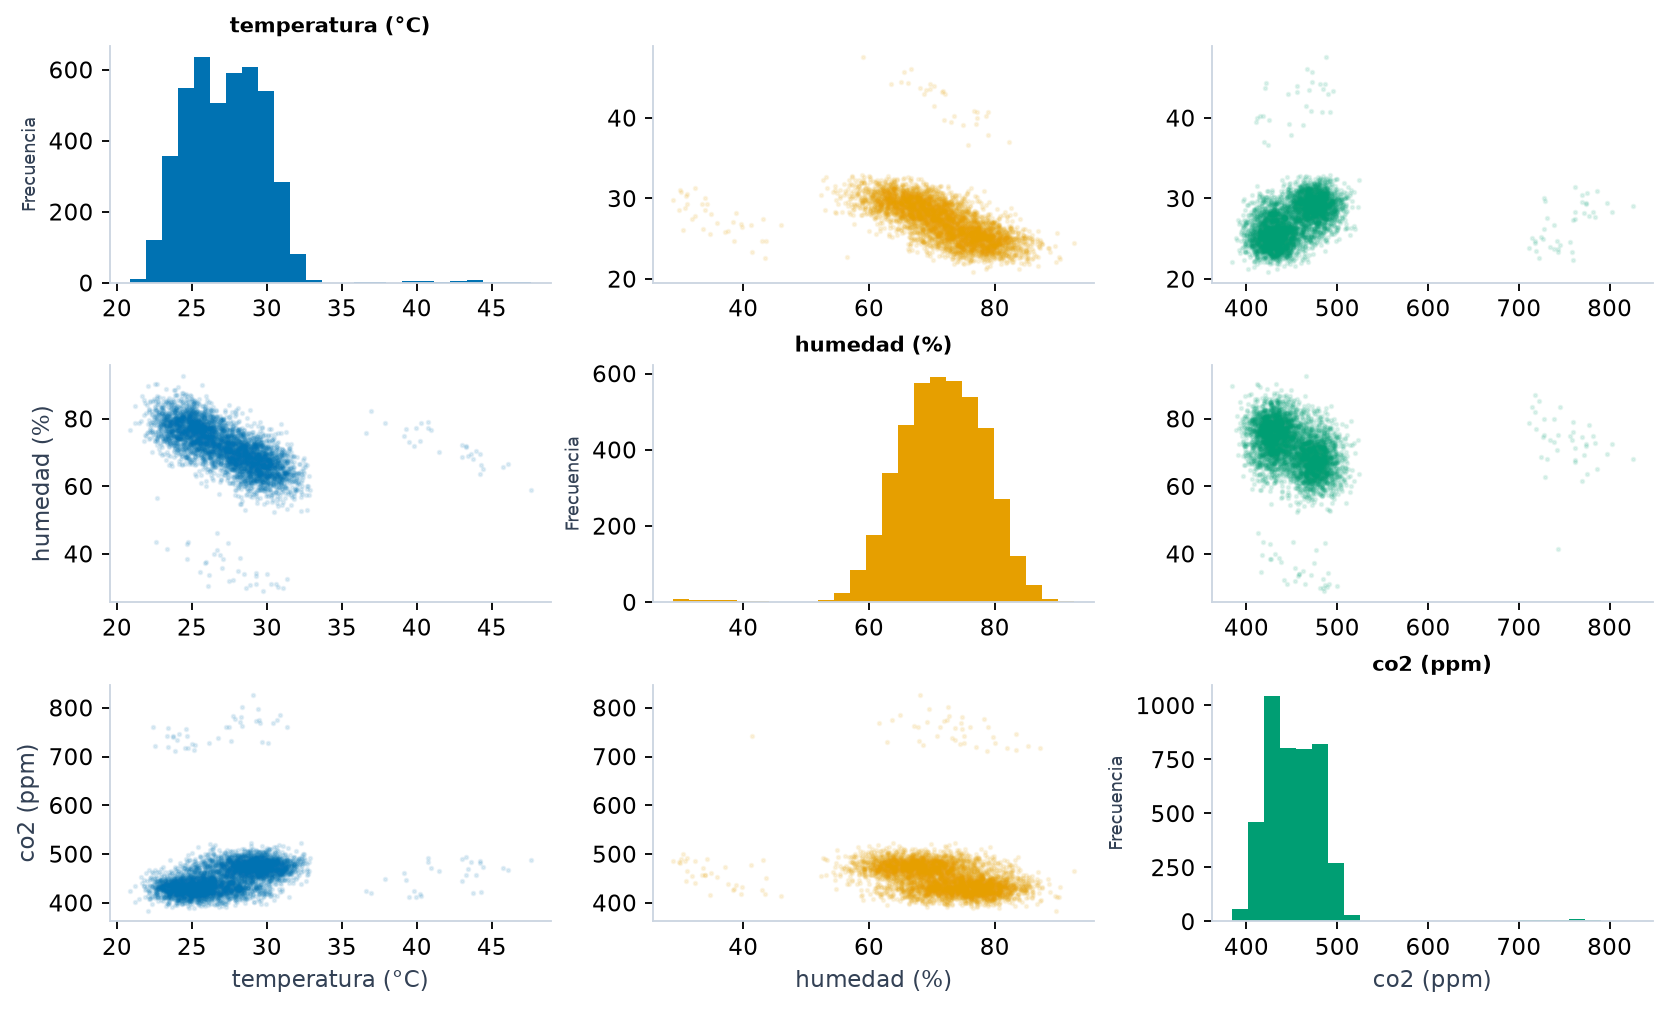

Resultado: La correlación temperatura-humedad es -0.590; temperatura-CO2 es 0.341.
Decisión: Inspeccionar dependencias y diferencias entre estaciones, y recalcular correlaciones excluyendo anomalías para analizar sensibilidad.
Límite: La relación inversa entre humedad y temperatura fue introducida por el generador. Los puntos extremos alteran Pearson y no constituyen evidencia física de campo.

S05 · Áreas apiladas por ubicación
Método: Se apilan conteos diarios por ciudad. Se usa conteo para evitar sumar temperatura, humedad y CO2, magnitudes incompatibles.


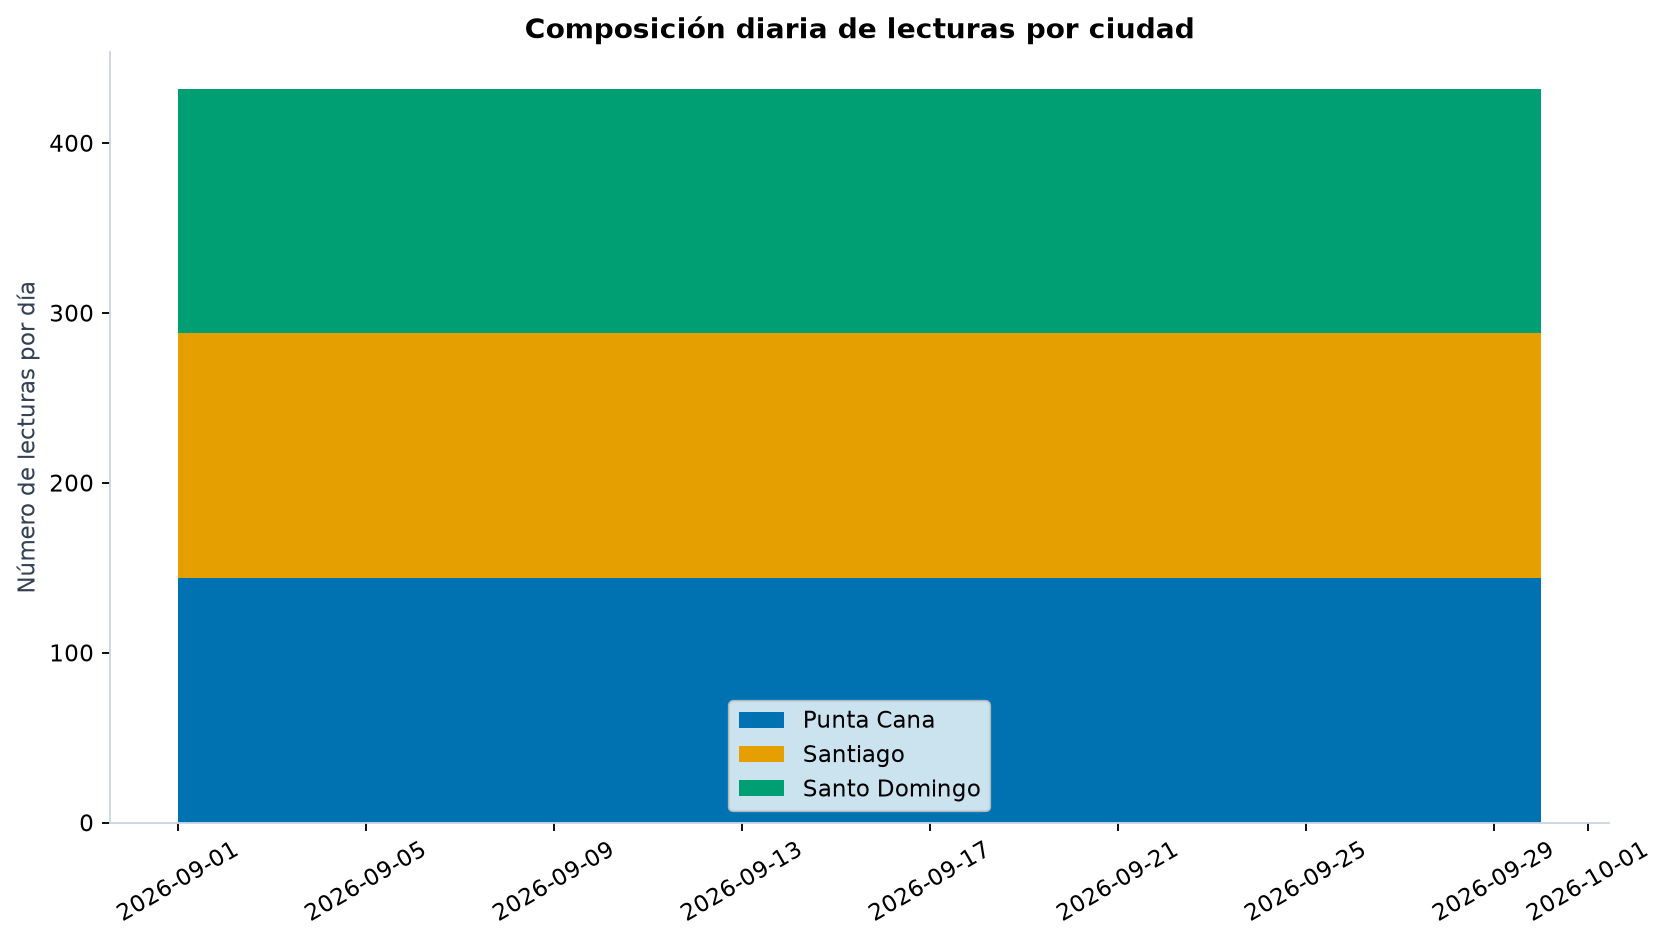

Resultado: Cada ciudad aporta 4,320 lecturas en 30 días; la participación diaria es 33.3% por ciudad.
Decisión: Identificar pérdida de cobertura si una banda disminuye en un despliegue real.
Límite: La estabilidad procede del muestreo sintético uniforme. La suma representa eventos y no intensidad de una variable física.

S06 · Detección de anomalías con MAD
Método: Por sensor y hora del día se calcula mediana y MAD. Se alerta si |valor - mediana| / (1.4826 × MAD) > 3.5. La etiqueta inyectada sólo se usa para evaluar.


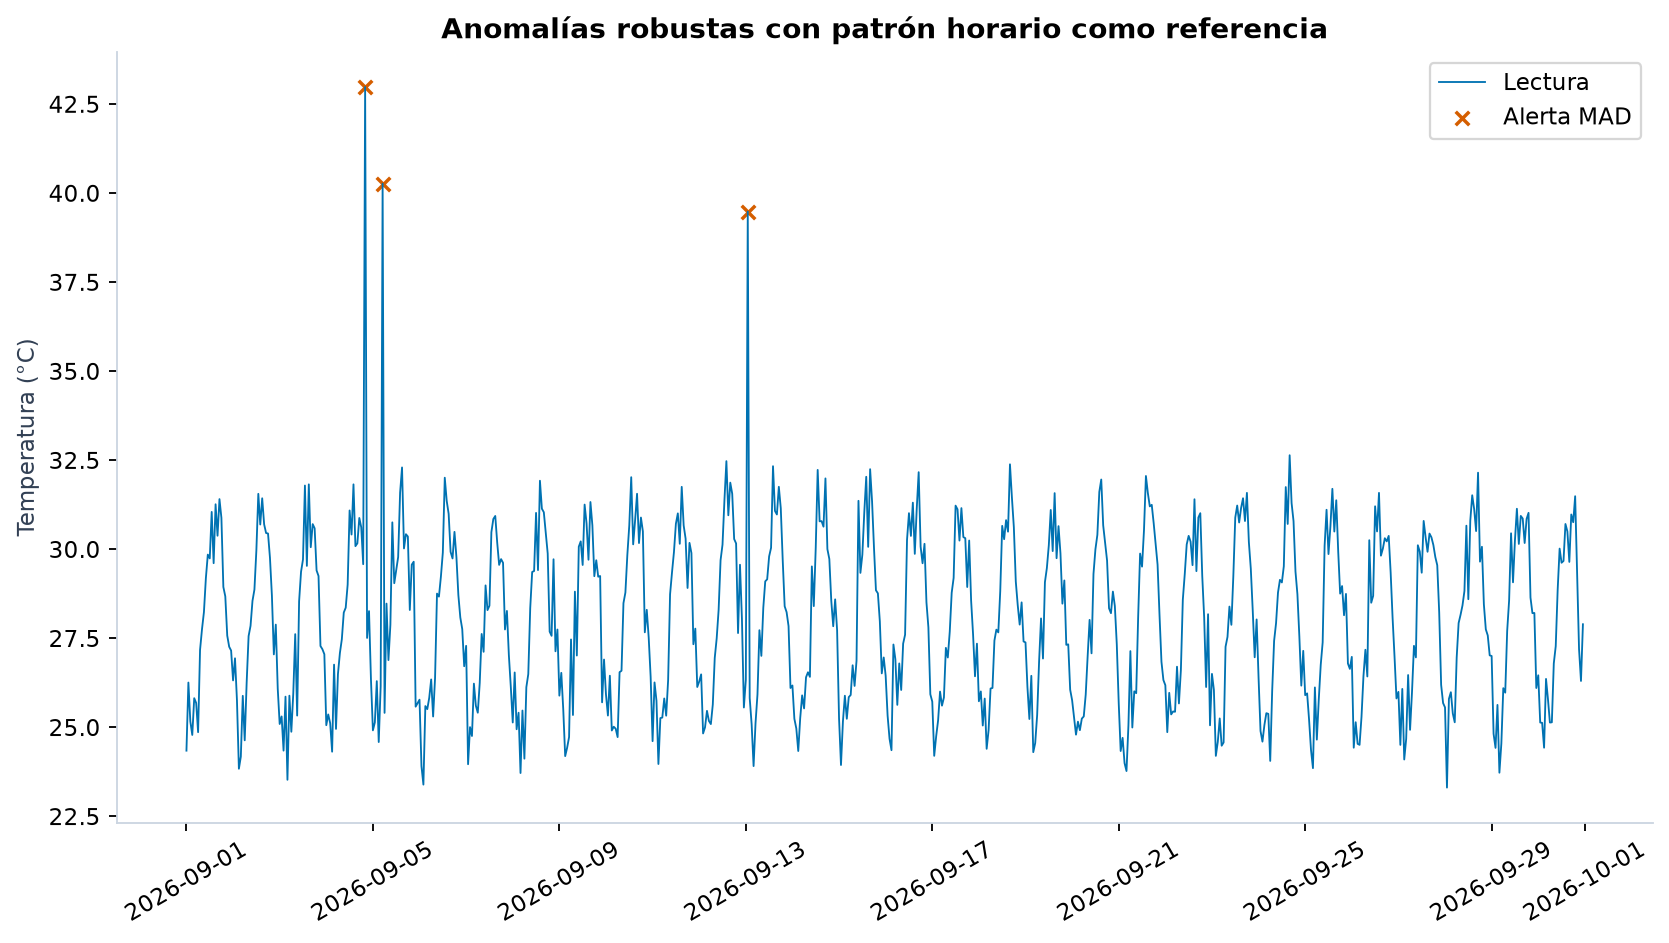

Resultado: En las 12,960 lecturas se detectan 137 alertas: 103 verdaderos positivos, 34 falsos positivos y 0 falsos negativos. Precisión 75.2%; sensibilidad 100.0%.
Decisión: Revisar alertas antes de eliminar datos y calibrar el umbral con una ventana histórica independiente.
Límite: La referencia usa todo septiembre: es detección retrospectiva, no validación predictiva. En producción debe entrenarse sobre datos previos y controlar MAD igual a cero.

S07 · Calendario de patrones diarios
Método: Se suman alertas por día local y se organizan en semanas de lunes a domingo. Celdas fuera de septiembre permanecen vacías.


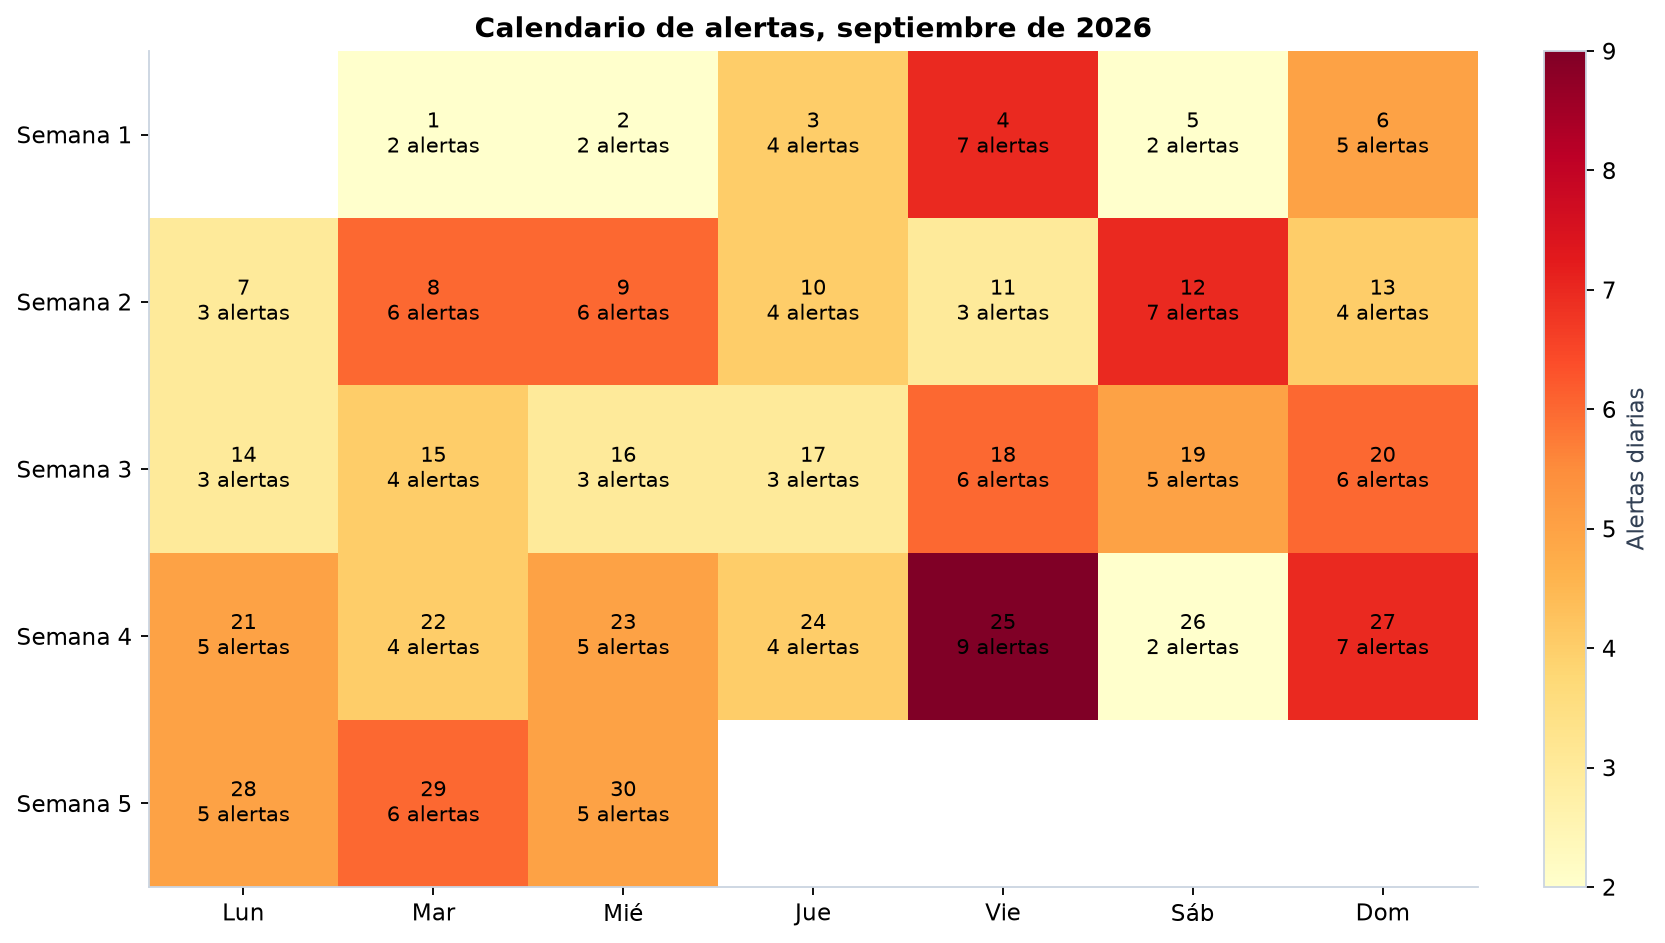

Resultado: El mayor conteo corresponde al 2026-09-25: 9 alertas sobre 432 lecturas diarias.
Decisión: Comparar alertas diarias con volumen de lecturas para localizar jornadas de revisión.
Límite: Sólo hay un mes de datos simulados. El máximo no confirma un patrón semanal estable ni una falla real.

S08 · Red de relaciones entre sensores
Método: Se crea un enlace entre dos sensores cuando comparten station. La posición es un diseño de red; no expresa coordenadas geográficas.


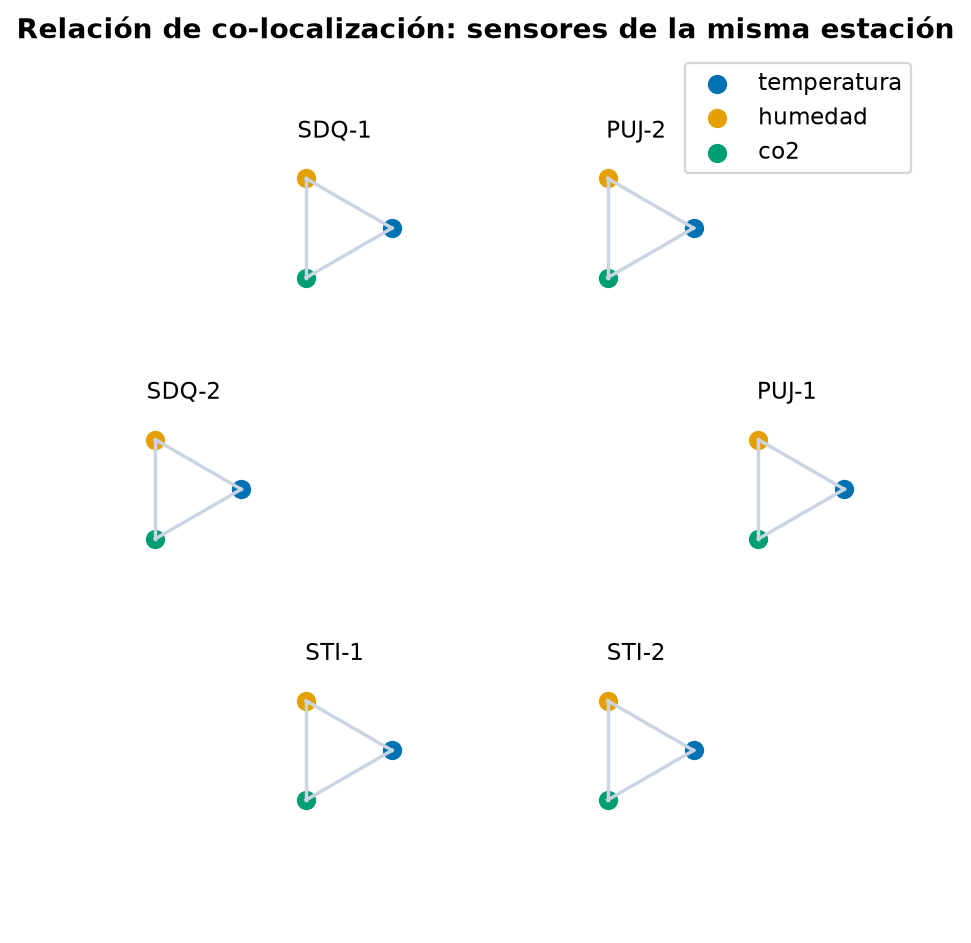

Resultado: La red tiene 18 sensores, 18 relaciones y seis grupos de tres sensores.
Decisión: Examinar qué magnitudes se observan conjuntamente y organizar validaciones por estación.
Límite: La relación es de co-localización definida en el esquema sintético. No representa conexiones físicas, tráfico de red ni causalidad.

S09 · Dispersión 3D: valor, ubicación y tiempo
Método: Se usa sólo temperatura para mantener una unidad coherente. Se toma una fila de cada doce y se codifica la estación como índice categórico.


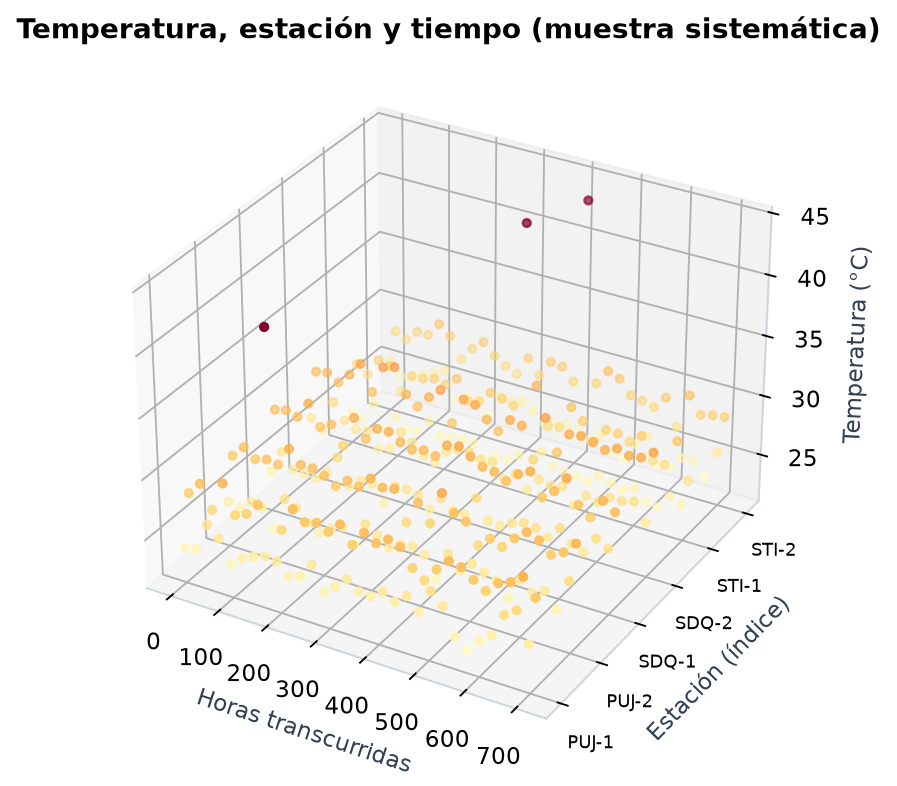

Resultado: El gráfico contiene 360 puntos de 4,320 lecturas de temperatura.
Decisión: Rotar y explorar el gráfico para localizar valores altos y comparar con las series temporales completas.
Límite: La distancia entre índices de estación no es distancia geográfica. El muestreo reduce carga y puede omitir anomalías; el detector utiliza todas las lecturas.

S10 · Dashboard de monitoreo simulado
Método: El dashboard incorpora controles de reproducir, pausar y reiniciar. Cada segundo agrega una lectura histórica de SDQ-1 a una ventana de 48 puntos.


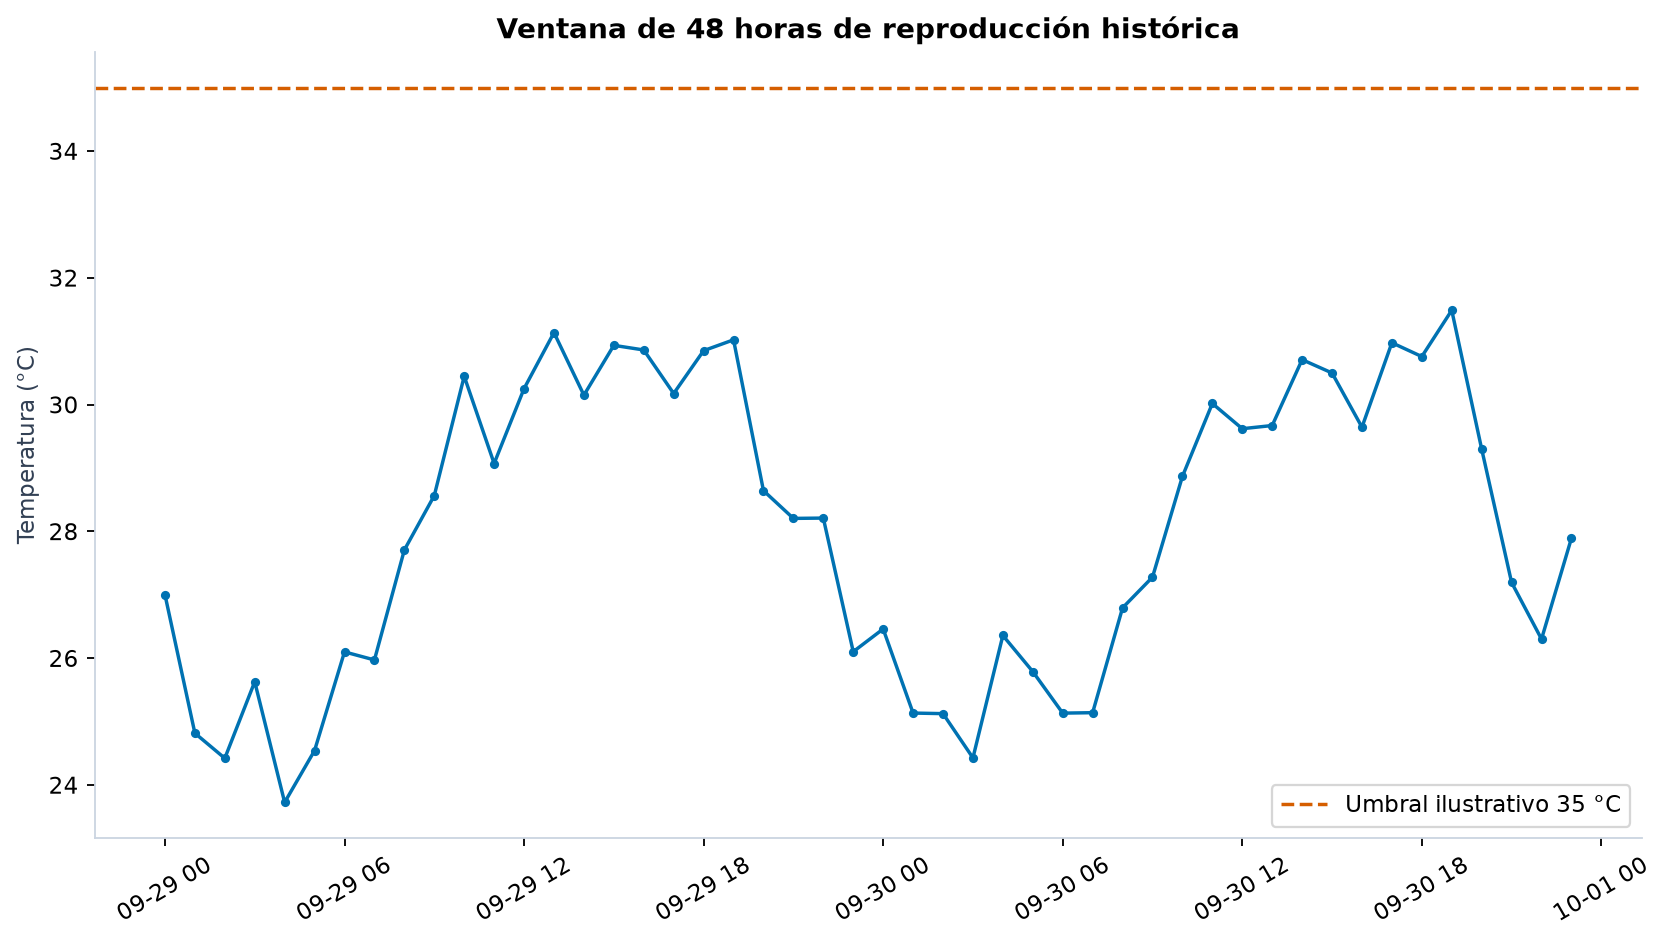

Resultado: La última lectura histórica de SDQ-1 es 27.89 °C, registrada el 30/09/2026 23:00.
Decisión: Usar la reproducción para probar controles, alertas visuales y actualización de una serie antes de conectar un flujo real.
Límite: Un segundo de reproducción equivale a una hora histórica. No hay streaming desde MongoDB ni medición ambiental en vivo. El umbral de 35 °C es ilustrativo.



In [6]:
meta = json.loads((root / 'docs/visualizaciones.json').read_text())
for item in [m for m in meta if m['id'].startswith('S')]:
    print(item['id'] + ' · ' + item['title'])
    print('Método:', item['method'])
    display(Image(filename=str(root / 'figuras' / (item['id'] + '.png')), width=900))
    print('Resultado:', item['insight'])
    print('Decisión:', item['decision'])
    print('Límite:', item['limit'])
    print()

## Dashboard y conexiones

Abre `dashboard/index.html` en un navegador. N01 permite filtrar país, H01 departamento y S06/S10 sensor. S10 reproduce historia; no consulta un flujo real.

Para comprobar los tres gestores, completa `config/.env` y ejecuta `python src/conexiones.py verificar`. Esa operación sólo se realiza al disponer del acceso; no se inventan capturas exitosas.

El informe final está en `informe/salida/`. La guía de instalación está en `README.md` y `COMO_CORRER.md`.